# Generalized Railway Platform Allocation — Exploratory High-Scale Stress Test (V11)

**Purpose:** one final exploratory experiment after the V10 encoding/feasibility study. V11 asks whether the relative behaviour of **one-hot vs domain-wall** and **SA vs SQA** changes when the input grows beyond 2,048 trains. It is not intended to extend the main paper benchmark or to make a new quantum-advantage claim.

**Sampler sizes:** 2,048, 4,096 and 8,192 trains. The 2,048-train datasets overlap the previous generator design and serve as a reference. Each size uses two independent seeds per synthetic difficulty (low, medium, high). Both encodings and algorithms receive matched reads, sweeps and repeat indices.

**16,384-train limit:** build/resource preflight only (one instance per difficulty in FULL mode). No SA or SQA sampling is attempted at 16,384. The preflight generates one instance per difficulty and records exact variable counts plus conservative upper bounds on quadratic interactions and penalty magnitudes. It does not materialize full 16,384-train QUBOs or invoke SA/SQA. If an estimate exceeds the declared preflight cap, that is reported rather than sampled.

**Efficiency and scope:** the interval-conflict generator is implemented with a sweep-line algorithm to avoid the previous quadratic pairwise scan. The V10 sample-guided repair is disabled in V11 so the stress test focuses on raw sampler behaviour and does not spend substantial time repairing thousands of reads. V10 remains the source for the separate repair analysis.

**Conditional confirmation:** if an encoding/algorithm combination produces zero valid raw reads across all 8,192-train MAIN datasets, V11 runs a separately labelled higher-budget confirmation (one selected seed per difficulty, 64 reads, 400 sweeps). These confirmation runs are not mixed into the primary scaling summary.

**Interpretation:** SQA is an OpenJij classical simulation, not quantum hardware. All schedules, nominal platforms, coach counts and conflicts are synthetic and station-independent. After V11, the planned experimental work stops and the project moves to paper finalization.


## 0. Environment setup
Run if needed, then restart the kernel.

In [1]:
%pip install -q openjij numpy pandas matplotlib psutil

Note: you may need to restart the kernel to use updated packages.


## 1. Imports and machine information

In [2]:
import sys, platform, time, math, json, itertools, random, importlib.metadata, warnings, os, gc
from pathlib import Path
from typing import Dict, List, Tuple, Optional, Any
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import openjij as oj
except ImportError as exc:
    raise ImportError("OpenJij is required. Install it in this notebook kernel, then restart the kernel.") from exc

try:
    import psutil
    RAM_GB = round(psutil.virtual_memory().total / 1024**3, 2)
except Exception:
    psutil = None
    RAM_GB = None
try:
    OPENJIJ_VERSION = importlib.metadata.version("openjij")
except Exception:
    OPENJIJ_VERSION = getattr(oj, "__version__", "version not exposed")

print("Python:", sys.version.split()[0])
print("OS:", platform.platform())
print("CPU:", platform.processor() or "not exposed")
print("RAM (GB):", RAM_GB)
print("OpenJij:", OPENJIJ_VERSION)

Python: 3.12.12
OS: Windows-11-10.0.26300-SP0
CPU: Intel64 Family 6 Model 143 Stepping 8, GenuineIntel
RAM (GB): 127.65
OpenJij: 0.12.2


## 2. Pre-registered V11 design and execution mode

Run `PILOT` first. After inspecting the pilot, change to `FULL` and restart the kernel. PILOT runs the 2,048- and 4,096-train tiers; FULL adds 8,192-train sampling and the 16,384-train structural resource preflight. Output folders are mode-specific.


In [3]:
# V11 is the final exploratory high-input stress test.
# Run PILOT first; after reviewing it, change to FULL and restart the kernel.
STUDY_MODE = "FULL"  # "PILOT" or "FULL"
RUN_EXPERIMENT = True
RUN_8192_BUDGET_CONFIRMATION = True
RUN_16384_PREFLIGHT = True
RUN_PLATFORM_ORDER_PROBE = False  # Platform-order behaviour was already probed in V7.1/V10.
RUN_REPAIR_POSTPROCESSING = False  # Repair was separately evaluated in V10; keep V11 focused on raw samples.

N_PLATFORMS = 6
LONG_PLATFORM_COUNT = 4
LONG_TRAIN_COACH_THRESHOLD = 24
CLEARANCE_MIN = 5  # Declared modelling assumption, in minutes.
DIFFICULTIES = ["low", "medium", "high"]
GREEDY_RESTARTS = 5
REPAIR_RESTARTS = 5  # Kept for function compatibility; V11 does not invoke repair.
SEED_BASE = 1110000

# Retain the V9/V9.1/V10 station-independent synthetic generator parameters.
DIFFICULTY_CONFIG = {
    "low":    {"dwell_min": 12, "dwell_max": 20, "delay_max_min": 3,
               "target_utilization": 0.55, "nominal_witness_probability": 0.80},
    "medium": {"dwell_min": 15, "dwell_max": 25, "delay_max_min": 8,
               "target_utilization": 0.70, "nominal_witness_probability": 0.55},
    "high":   {"dwell_min": 18, "dwell_max": 30, "delay_max_min": 15,
               "target_utilization": 0.84, "nominal_witness_probability": 0.30},
}

if STUDY_MODE.upper() == "PILOT":
    TRAIN_COUNTS = [2048, 4096]
    SEEDS_BY_SIZE = {2048: [11], 4096: [11]}
    ORDER_PROBE_DATASETS = []
    N_ALTERNATE_PLATFORM_ORDERS = 0
elif STUDY_MODE.upper() == "FULL":
    TRAIN_COUNTS = [2048, 4096, 8192]
    SEEDS_BY_SIZE = {2048: [11, 22], 4096: [11, 22], 8192: [11, 22]}
    ORDER_PROBE_DATASETS = []
    N_ALTERNATE_PLATFORM_ORDERS = 0
else:
    raise ValueError("STUDY_MODE must be PILOT or FULL")

ENCODINGS = ["one_hot", "domain_wall"]
ALGORITHMS = ["SA", "SQA"]
# Matched baseline budget at all sampler sizes. The optional 8,192 confirmation is separate.
BUDGET_BY_SIZE = {
    "small":  {"repeats": 2, "num_reads": 16, "num_sweeps": 200},
    "medium": {"repeats": 2, "num_reads": 16, "num_sweeps": 200},
    "large":  {"repeats": 2, "num_reads": 16, "num_sweeps": 200},
}
MAX_QUBO_VARIABLES = 60000
MAX_QUBO_INTERACTIONS = 1000000

# Conditional 8,192-train confirmation: one high-budget run per difficulty,
# encoding and algorithm, but only when that combination has zero valid MAIN reads.
ESCALATION_N = 8192
ESCALATION_DATA_SEED = 11
ESCALATION_READS = 64
ESCALATION_SWEEPS = 400
ESCALATION_REPEAT_ID = 99

# 16,384 is build-only. These are preflight acceptance thresholds, not sampler limits.
PREFLIGHT_N = 16384
PREFLIGHT_MAX_VARIABLES = 120000
PREFLIGHT_MAX_INTERACTIONS = 2000000
PREFLIGHT_GREEDY_RESTARTS = 1


def budget_tier(n):
    return "large"

EXPECTED_DATASETS = sum(len(SEEDS_BY_SIZE[n]) for n in TRAIN_COUNTS) * len(DIFFICULTIES)
EXPECTED_MAIN_CALLS = EXPECTED_DATASETS * len(ENCODINGS) * len(ALGORITHMS) * BUDGET_BY_SIZE["large"]["repeats"]
EXPECTED_ORDER_CALLS = 0
EXPECTED_CALLS = EXPECTED_MAIN_CALLS
print("Study mode:", STUDY_MODE)
print("Sampler train sizes:", TRAIN_COUNTS)
print("Expected independent datasets:", EXPECTED_DATASETS)
print("Planned MAIN sampler calls:", EXPECTED_MAIN_CALLS)
print("Conditional 8,192 confirmation: up to", len(DIFFICULTIES)*len(ENCODINGS)*len(ALGORITHMS), "additional calls")
print("16,384-train preflight:", bool(RUN_16384_PREFLIGHT and STUDY_MODE.upper()=="FULL"), "(structural resource estimate only; no full QUBO or sampling)")
print("Encodings:", ENCODINGS, "Algorithms:", ALGORITHMS)
print("Matched MAIN budget:", BUDGET_BY_SIZE["large"])
print("Repair post-processing enabled:", RUN_REPAIR_POSTPROCESSING)
print("Main QUBO caps:", MAX_QUBO_VARIABLES, "variables /", MAX_QUBO_INTERACTIONS, "interactions")


Study mode: FULL
Sampler train sizes: [2048, 4096, 8192]
Expected independent datasets: 18
Planned MAIN sampler calls: 144
Conditional 8,192 confirmation: up to 12 additional calls
16,384-train preflight: True (structural resource estimate only; no full QUBO or sampling)
Encodings: ['one_hot', 'domain_wall'] Algorithms: ['SA', 'SQA']
Matched MAIN budget: {'repeats': 2, 'num_reads': 16, 'num_sweeps': 200}
Repair post-processing enabled: False
Main QUBO caps: 60000 variables / 1000000 interactions


## 3. Synthetic railway instance generator

The V9.1 generator is retained. Only the conflict-edge construction is optimized with a sweep-line implementation, which is checked against the original pairwise predicate on small instances. Its feasible witness is used for generator validation and as a documented fallback for constructing a valid penalty bound only; it is never passed to an annealing sampler.


In [4]:
def generate_instance(n_trains: int, difficulty: str, seed: int,
                      n_platforms: int = N_PLATFORMS,
                      long_platform_count: int = LONG_PLATFORM_COUNT,
                      clearance_min: int = CLEARANCE_MIN) -> pd.DataFrame:
    """Generate an always-feasible interval-allocation instance.

    The hidden witness uses the long-capable platform pool for long trains and the
    short-only platform pool for short trains. Intervals are sequenced independently
    on each witness platform. The full eligibility rules remain unchanged for solvers.
    The witness is exported for audit, but never passed to QUBO or samplers.
    """
    if difficulty not in DIFFICULTY_CONFIG:
        raise ValueError(f"Unknown difficulty: {difficulty}")
    if n_trains < 1 or n_platforms < 2:
        raise ValueError("Need at least one train and two platforms")
    if not 1 <= long_platform_count <= n_platforms:
        raise ValueError("Invalid long-platform count")
    cfg = DIFFICULTY_CONFIG[difficulty]
    rng = np.random.default_rng(seed)
    drafts = []
    witness_loads = {p:0 for p in range(n_platforms)}

    # Determine train attributes and a hidden feasible witness platform.
    for i in range(n_trains):
        coaches = int(rng.integers(10,31))
        is_long = coaches >= LONG_TRAIN_COACH_THRESHOLD
        eligible = list(range(long_platform_count)) if is_long else list(range(n_platforms))
        # The generator witness uses disjoint lane pools: long-capable platforms
        # for long trains, and the remaining short-only platforms for short trains.
        # Solver eligibility is unchanged: short trains may still use every platform.
        witness_pool = list(range(long_platform_count)) if is_long else list(range(long_platform_count,n_platforms))
        if not witness_pool:
            raise ValueError("At least one short-only platform is required for this witness generator")
        min_load = min(witness_loads[p] for p in witness_pool)
        balanced_candidates = [p for p in witness_pool if witness_loads[p] == min_load]
        witness_platform = int(rng.choice(balanced_candidates))
        witness_loads[witness_platform] += 1
        dwell = int(rng.integers(cfg["dwell_min"],cfg["dwell_max"]+1))
        delay = int(rng.integers(0,cfg["delay_max_min"]+1))
        drafts.append({
            "train_index":i,"train_id":f"T{i+1:05d}","coaches":coaches,
            "is_long":bool(is_long),"eligible_platforms":eligible,
            "witness_platform":witness_platform,"dwell_min":dwell,"delay_min":delay,
        })

    # Create a separate chronological lane on each witness platform.
    # Mean idle gap is selected from target utilisation; this keeps load intensity
    # approximately comparable as N grows instead of overloading a fixed time horizon.
    platform_orders = {p:[] for p in range(n_platforms)}
    for item in drafts:
        platform_orders[item["witness_platform"]].append(item["train_index"])
    for p in range(n_platforms):
        rng.shuffle(platform_orders[p])

    times = {}
    mean_dwell = (cfg["dwell_min"] + cfg["dwell_max"]) / 2.0
    target_u = float(cfg["target_utilization"])
    mean_occupied = mean_dwell + int(clearance_min)
    mean_gap = mean_occupied * (1.0-target_u) / target_u
    for p, order in platform_orders.items():
        cursor = 60  # warm-up offset ensures scheduled arrival remains nonnegative after delay
        for i in order:
            gap = max(0,int(round(rng.exponential(mean_gap)))) if mean_gap > 0 else 0
            actual_arrival = cursor + gap
            item = drafts[i]
            actual_departure = actual_arrival + item["dwell_min"]
            scheduled_arrival = actual_arrival - item["delay_min"]
            times[i] = {
                "scheduled_arrival_min":scheduled_arrival,
                "scheduled_departure_min":scheduled_arrival + item["dwell_min"],
                "actual_arrival_min":actual_arrival,
                "actual_departure_min":actual_departure,
            }
            cursor = actual_departure + int(clearance_min)

    rows=[]
    for item in drafts:
        eligible=item["eligible_platforms"]
        witness=item["witness_platform"]
        if rng.random() < float(cfg["nominal_witness_probability"]):
            nominal=witness
        else:
            alternatives=[p for p in eligible if p != witness]
            nominal=int(rng.choice(alternatives)) if alternatives else witness
        rows.append({
            **item,**times[item["train_index"]],
            "nominal_platform":int(nominal),
            "difficulty":difficulty,"seed":int(seed),
            "target_utilization":target_u,
            "nominal_witness_probability":float(cfg["nominal_witness_probability"]),
        })
    return pd.DataFrame(rows)


def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int,int]]:
    """Return every overlapping interval pair using an O((N+E) log N) sweep line.

    Intervals are half-open [actual_arrival, actual_departure + clearance), matching
    V11's predicate exactly. The active set contains only intervals whose end is
    strictly greater than the current start, so touching endpoints are not conflicts.
    """
    import heapq
    starts = df["actual_arrival_min"].astype(int).to_numpy()
    ends = (df["actual_departure_min"].astype(int) + int(clearance_min)).to_numpy()
    order = sorted(range(len(df)), key=lambda i: (int(starts[i]), int(i)))
    expiry_heap = []
    active = set()
    edges = []
    for i in order:
        start_i = int(starts[i])
        while expiry_heap and expiry_heap[0][0] <= start_i:
            _, expired_i = heapq.heappop(expiry_heap)
            active.discard(expired_i)
        for j in active:
            edges.append((min(i, j), max(i, j)))
        active.add(i)
        heapq.heappush(expiry_heap, (int(ends[i]), i))
    edges.sort()
    return edges


def max_interval_concurrency(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN,
                             long_only: bool = False) -> int:
    subset=df[df.is_long] if long_only else df
    events=[]
    for row in subset.itertuples():
        events.append((int(row.actual_arrival_min),1))
        events.append((int(row.actual_departure_min)+int(clearance_min),-1))
    # End events before start events at equal time: intervals are half-open.
    events.sort(key=lambda x:(x[0],x[1]))
    active=peak=0
    for _,delta in events:
        active+=delta
        peak=max(peak,active)
    return int(peak)


def assignment_cost(assignment: Dict[int,int], df: pd.DataFrame) -> int:
    return int(sum(int(assignment[i]) != int(df.iloc[i].nominal_platform) for i in range(len(df))))


def validate_assignment(assignment, df, conflicts):
    n=len(df)
    if assignment is None or len(assignment)!=n or set(assignment)!=set(range(n)):
        return False,["missing_train_assignment"]
    eligible_lists=df["eligible_platforms"].tolist()
    violations=[]
    for i,p in assignment.items():
        if int(p) not in eligible_lists[i]:
            violations.append(f"ineligible_platform_train_{i}")
    for i,j in conflicts:
        if int(assignment[i])==int(assignment[j]):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations)==0,violations



def conflict_density(n_trains: int, conflicts: List[Tuple[int,int]]) -> float:
    possible=n_trains*(n_trains-1)/2
    return len(conflicts)/possible if possible else 0.0

print("Capacity-aware synthetic generator and validators defined.")

Capacity-aware synthetic generator and validators defined.


## 4. Conflict, objective, validation and dataset helpers

In [5]:
def interval_conflicts(df: pd.DataFrame, clearance_min: int = CLEARANCE_MIN) -> List[Tuple[int,int]]:
    """Return overlap edges with a sweep-line algorithm, preserving half-open semantics."""
    import heapq
    starts=df["actual_arrival_min"].astype(int).to_numpy()
    ends=(df["actual_departure_min"].astype(int).to_numpy()+int(clearance_min))
    order=sorted(range(len(df)),key=lambda i:(int(starts[i]),i))
    expiry_heap=[]; active=set(); edges=[]
    for i in order:
        start_i=int(starts[i])
        while expiry_heap and expiry_heap[0][0] <= start_i:
            _,expired=heapq.heappop(expiry_heap)
            active.discard(expired)
        for j in active:
            edges.append((min(i,j),max(i,j)))
        active.add(i)
        heapq.heappush(expiry_heap,(int(ends[i]),i))
    edges.sort()
    return edges


def assignment_cost(assignment: Dict[int,int], df: pd.DataFrame) -> int:
    nominal = df["nominal_platform"].astype(int).to_numpy()
    return int(sum(int(assignment[i]) != int(nominal[i]) for i in range(len(nominal))))


def validate_assignment(assignment, df, conflicts):
    n=len(df)
    if assignment is None or len(assignment)!=n or set(assignment)!=set(range(n)):
        return False,["missing_train_assignment"]
    eligible_lists=df["eligible_platforms"].tolist()
    violations=[]
    for i,p in assignment.items():
        if int(p) not in eligible_lists[i]:
            violations.append(f"ineligible_platform_train_{i}")
    for i,j in conflicts:
        if int(assignment[i])==int(assignment[j]):
            violations.append(f"overlap_conflict_{i}_{j}")
    return len(violations)==0,violations



def conflict_density(n_trains, conflicts):
    possible=n_trains*(n_trains-1)/2
    return len(conflicts)/possible if possible else 0.0


def max_interval_concurrency(df, clearance_min=CLEARANCE_MIN, long_only=False):
    subset=df[df.is_long] if long_only else df
    events=[]
    for row in subset.itertuples():
        events.append((int(row.actual_arrival_min),1))
        events.append((int(row.actual_departure_min)+int(clearance_min),-1))
    events.sort(key=lambda x:(x[0],x[1]))
    active=peak=0
    for _,delta in events:
        active+=delta
        peak=max(peak,active)
    return int(peak)


def make_dataset_id(n, difficulty, seed):
    return f"N{n}_{difficulty.upper()}_S{seed}"

def permute_platform_labels(df,permutation):
    """Relabel platform IDs without changing the categorical allocation problem."""
    out=df.copy(deep=True)
    out["nominal_platform"]=out.nominal_platform.map(lambda p:int(permutation[int(p)]))
    out["eligible_platforms"]=out.eligible_platforms.map(lambda ps:sorted(int(permutation[int(p)]) for p in ps))
    out["witness_platform"]=out.witness_platform.map(lambda p:int(permutation[int(p)]))
    return out


## 5. Classical Greedy baselines

Both established baselines are retained. The first uses the interval-reserved platform-pool strategy. The second uses most-constrained-first ordering without witness-pool reservation.

In [6]:
def greedy_assignment(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                      seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Time-ordered interval Greedy with the established platform-pool reservation rule.

    Arrays are materialized once so large-N runs do not repeatedly index pandas rows.
    """
    n=len(df)
    arrivals=df["actual_arrival_min"].astype(int).to_numpy()
    departures=df["actual_departure_min"].astype(int).to_numpy()
    nominal=df["nominal_platform"].astype(int).to_numpy()
    is_long=df["is_long"].astype(bool).to_numpy()
    eligible_lists=[[int(p) for p in ps] for ps in df["eligible_platforms"].tolist()]
    master_rng=np.random.default_rng(seed)
    best=None; best_cost=float("inf")
    short_only_platforms=set(range(LONG_PLATFORM_COUNT,N_PLATFORMS))
    for _ in range(max(1,int(restarts))):
        rng=np.random.default_rng(int(master_rng.integers(0,2**31-1)))
        tie=rng.random(n)
        order=sorted(range(n),key=lambda i:(arrivals[i],not is_long[i],tie[i],i))
        available_at={p:-10**18 for p in range(N_PLATFORMS)}
        platform_load={p:0 for p in range(N_PLATFORMS)}
        assigned={}
        for i in order:
            start=int(arrivals[i])
            available=[p for p in eligible_lists[i] if available_at[p] <= start]
            if not is_long[i]:
                short_available=[p for p in available if p in short_only_platforms]
                if short_available: available=short_available
            if not available: break
            jitter={p:float(rng.random()) for p in available}
            chosen=min(available,key=lambda p:(p!=int(nominal[i]),platform_load[p],jitter[p],p))
            assigned[i]=chosen
            available_at[chosen]=int(departures[i])+CLEARANCE_MIN
            platform_load[chosen]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                if cost<best_cost: best,best_cost=assigned.copy(),cost
                if best_cost==0: break
    return best


def greedy_assignment_mrv(df: pd.DataFrame, conflicts: List[Tuple[int,int]],
                          seed: int = 0, restarts: int = GREEDY_RESTARTS) -> Optional[Dict[int,int]]:
    """Generic MRV/degree Greedy using public eligibility and conflict information only."""
    n=len(df)
    neighbours=[set() for _ in range(n)]
    for i,j in conflicts:
        neighbours[i].add(j); neighbours[j].add(i)
    degrees=[len(x) for x in neighbours]
    eligible_lists=[[int(p) for p in ps] for ps in df["eligible_platforms"].tolist()]
    arrivals=df["actual_arrival_min"].astype(int).to_numpy()
    dwells=(df["actual_departure_min"].astype(int)-df["actual_arrival_min"].astype(int)).to_numpy()
    nominal=df["nominal_platform"].astype(int).to_numpy()
    domain_sizes=[len(x) for x in eligible_lists]
    master_rng=np.random.default_rng(seed)
    best_assignment=None; best_cost=float("inf")
    for _ in range(max(1,int(restarts))):
        rng=np.random.default_rng(int(master_rng.integers(0,2**31-1)))
        tie=rng.random(n)
        order=sorted(range(n),key=lambda i:(domain_sizes[i],-degrees[i],int(arrivals[i]),-int(dwells[i]),tie[i],i))
        assigned={}; platform_load={p:0 for p in range(N_PLATFORMS)}
        for i in order:
            forbidden={assigned[j] for j in neighbours[i] if j in assigned}
            available=[p for p in eligible_lists[i] if p not in forbidden]
            if not available: break
            jitter={p:float(rng.random()) for p in available}
            chosen=min(available,key=lambda p:(p!=int(nominal[i]),platform_load[p],jitter[p],p))
            assigned[i]=chosen; platform_load[chosen]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                if cost<best_cost: best_assignment,best_cost=assigned.copy(),cost
                if best_cost==0: break
    return best_assignment

print("Both Greedy baselines defined; no exact solver is run in V11.")


Both Greedy baselines defined; no exact solver is run in V11.


## 6. Matched one-hot and domain-wall QUBO builders

The V11 encoding definitions and penalty proofs are retained. The same problem instance and validated feasible upper bound are used for both encodings. V11 raises the QUBO resource caps only to permit exploratory builds at 8,192 trains; 16,384 is handled in a separate build-only preflight and is never sampled.


In [7]:
# Boolean polynomial maps sorted tuples of variable names to coefficients.
# The empty tuple represents the constant term; x*x is reduced to x for binary x.
def poly_add(a, b, scale=1.0):
    out=dict(a)
    for key,value in b.items():
        out[key]=out.get(key,0.0)+float(scale)*float(value)
    return {k:v for k,v in out.items() if abs(v)>1e-12}


def poly_mul(a,b):
    out={}
    for ka,va in a.items():
        for kb,vb in b.items():
            key=tuple(sorted(set(ka).union(kb)))
            if len(key)>2:
                raise ValueError(f"Polynomial degree exceeded two: {key}")
            out[key]=out.get(key,0.0)+float(va)*float(vb)
    return {k:v for k,v in out.items() if abs(v)>1e-12}


def poly_accumulate(target,addition,scale=1.0):
    """Add a small polynomial into a large accumulator in-place (linear time in addition)."""
    for key,value in addition.items():
        updated=target.get(key,0.0)+float(scale)*float(value)
        if abs(updated)<=1e-12:
            target.pop(key,None)
        else:
            target[key]=updated
    return target


def pvar(name):
    return {(str(name),):1.0}


def paffine(constant=0.0, coefficients=None):
    out={}
    if abs(constant)>1e-12: out[()]=float(constant)
    for name,coef in (coefficients or {}).items():
        if abs(coef)>1e-12: out[(str(name),)]=out.get((str(name),),0.0)+float(coef)
    return {k:v for k,v in out.items() if abs(v)>1e-12}


def poly_to_qubo(poly):
    offset=float(poly.get((),0.0))
    Q={}
    for key,value in poly.items():
        if not key: continue
        qkey=(key[0],key[0]) if len(key)==1 else tuple(sorted(key))
        if len(key)>2: raise ValueError(f"Non-QUBO term: {key}")
        Q[qkey]=Q.get(qkey,0.0)+float(value)
    return {k:v for k,v in Q.items() if abs(v)>1e-12},offset


def add_qubo_term(Q,a,b,value):
    key=(a,b) if a<=b else (b,a)
    Q[key]=Q.get(key,0.0)+float(value)
    if abs(Q[key])<1e-12: del Q[key]


def build_one_hot(df, conflicts, feasible_upper_bound):
    """One-hot QUBO with lambda=U+1 for assignment and conflict penalties."""
    n=len(df); lam=float(feasible_upper_bound+1)
    if lam<=0 or not np.isfinite(lam): raise ValueError("Invalid one-hot penalty")
    Q={}; offset=0.0; y={}; variables=[]
    for i in range(n):
        eligible=[int(p) for p in df.iloc[i].eligible_platforms]
        names=[]
        for p in eligible:
            name=f"oh_{i}_{p}"; y[(i,p)]=name; variables.append(name); names.append(name)
            if p!=int(df.iloc[i].nominal_platform): add_qubo_term(Q,name,name,1.0)
        # lambda * (sum(x)-1)^2, using x^2=x.
        offset+=lam
        for name in names: add_qubo_term(Q,name,name,-lam)
        for a,b in itertools.combinations(names,2): add_qubo_term(Q,a,b,2.0*lam)
    for i,j in conflicts:
        common=set(map(int,df.iloc[i].eligible_platforms)).intersection(map(int,df.iloc[j].eligible_platforms))
        for p in common: add_qubo_term(Q,y[(i,p)],y[(j,p)],lam)
    return {"encoding":"one_hot","Q":Q,"offset":offset,"variables":variables,"y":y,
            "lambda_assign":lam,"lambda_conflict":lam,"penalties":{"assignment":lam,"conflict":lam},
            "feasible_upper_bound":int(feasible_upper_bound)}


def domain_wall_indicator_expr(ordinal, bit_names, n_choices):
    # Train-specific valid strings are 111...1100...00 over its sorted eligible list.
    if n_choices < 2:
        raise ValueError("Each train must have at least two eligible platforms")
    if ordinal == 0:
        return paffine(1.0, {bit_names[0]: -1.0})
    if ordinal == n_choices - 1:
        return pvar(bit_names[-1])
    return paffine(0.0, {bit_names[ordinal-1]: 1.0, bit_names[ordinal]: -1.0})


def build_domain_wall(df, conflicts, feasible_upper_bound, n_platforms=N_PLATFORMS):
    """Train-specific domain-wall QUBO with an analytically sufficient wall penalty.

    Each train is represented only over its sorted eligible-platform list. Its
    k eligible choices use k-1 bits; valid codewords are 111...1100...00.
    The indicators telescope to one for every bitstring. Each individual
    indicator is at most one, so the reassignment objective 1-y[nominal] is
    nonnegative even on non-monotone bitstrings.

    Let r_i be the number of forbidden 0->1 transitions in train i's bit chain.
    The indicator vector has negative mass r_i and positive mass r_i+1. Hence,
    for an edge (i,j), its indicator dot product is bounded below by
      -[r_i(r_j+1) + r_j(r_i+1)].
    If Rmax is the maximum possible rises for any train, this is no less than
      -(Rmax+1)(r_i+r_j).
    Summing over conflict edges gives a lower bound of
      -(Rmax+1)*max_degree*sum_i(r_i)
    for the unscaled conflict expression. Since the reassignment objective is
    nonnegative, setting
      lambda_wall = lambda_conflict*(Rmax+1)*max_degree + U + 2
    gives every wall-invalid state energy at least (U+2)*sum_i(r_i), which is
    strictly greater than the feasible incumbent U because an invalid chain has
    at least one rise. For wall-valid states, each indicator vector
    is one-hot and lambda_conflict=U+1 makes every conflicting state cost > U.

    Therefore every global QUBO minimizer is valid and has the categorical
    objective optimum. This is a ground-state guarantee, not a guarantee that
    finite-budget SA/SQA samples will reach a ground state.
    """
    n=len(df)
    U=int(feasible_upper_bound)
    if U < 0:
        raise ValueError("feasible_upper_bound must be non-negative")
    lam_conflict=float(U+1)
    poly_nonwall={}; bits={}; variables=[]; indicators={}; choices={}
    degrees=[0]*n
    for i,j in conflicts:
        degrees[i]+=1; degrees[j]+=1
    max_degree=max(degrees) if degrees else 0
    max_wall_rises=0

    for i in range(n):
        eligible=sorted(map(int,df.iloc[i].eligible_platforms))
        choices[i]=eligible
        n_choices=len(eligible)
        if n_choices < 2:
            raise ValueError(f"Train {i} has fewer than two eligible platforms")
        # A chain of n_choices-1 bits can contain at most floor((n_choices-1)/2) rises.
        max_wall_rises=max(max_wall_rises,(n_choices-1)//2)
        bit_names=[f"dw_{i}_d{k}" for k in range(n_choices-1)]
        bits[i]=bit_names; variables.extend(bit_names)
        nominal=int(df.iloc[i].nominal_platform)
        for ordinal,p in enumerate(eligible):
            expr=domain_wall_indicator_expr(ordinal,bit_names,n_choices)
            indicators[(i,p)]=expr
            if p!=nominal:
                poly_accumulate(poly_nonwall,expr,1.0)

    for i,j in conflicts:
        common=sorted(set(choices[i]).intersection(choices[j]))
        for p in common:
            poly_accumulate(poly_nonwall,
                             poly_mul(indicators[(i,p)],indicators[(j,p)]),
                             lam_conflict)

    lambda_wall=(lam_conflict*float(max_wall_rises+1)*float(max_degree)
                 +float(U)+2.0)
    poly=dict(poly_nonwall)
    for i in range(n):
        d=bits[i]
        for k in range(len(d)-1):
            # Forbidden 0->1 transition: d[k+1] * (1-d[k]).
            transition=poly_add(pvar(d[k+1]),poly_mul(pvar(d[k+1]),pvar(d[k])),-1.0)
            poly_accumulate(poly,transition,lambda_wall)

    Q,offset=poly_to_qubo(poly)
    return {"encoding":"domain_wall","Q":Q,"offset":offset,"variables":variables,
            "bits":bits,"choices":choices,"indicators":indicators,
            "lambda_conflict":lam_conflict,"lambda_wall":lambda_wall,
            "max_conflict_degree":max_degree,"max_wall_rises_per_train":max_wall_rises,
            "feasible_upper_bound":U,
            "penalties":{"conflict":lam_conflict,"domain_wall":lambda_wall}}


def qubo_metrics(Q,variables,offset):
    nvar=len(variables); interactions=sum(1 for a,b in Q if a!=b)
    coeffs=[abs(v) for v in Q.values() if abs(v)>1e-12]
    possible=nvar*(nvar-1)/2
    return {"n_variables":nvar,"n_linear_terms":sum(1 for a,b in Q if a==b),
            "n_quadratic_interactions":interactions,
            "interaction_density":interactions/possible if possible else 0.0,
            "max_abs_coefficient":max(coeffs) if coeffs else 0.0,
            "min_abs_nonzero_coefficient":min(coeffs) if coeffs else 0.0,
            "coefficient_dynamic_range":(max(coeffs)/min(coeffs)) if coeffs and min(coeffs)>0 else np.nan,
            "offset":float(offset)}


def evaluate_qubo(Q,offset,sample):
    total=float(offset)
    for (a,b),coef in Q.items(): total+=float(coef)*int(sample.get(a,0))*int(sample.get(b,0))
    return float(total)

## 7. Raw constraint diagnostics and sample-guided repair

Every returned unique sample is checked for all relevant constraint categories. The decoder does not stop after the first problem. The repair procedure uses the sample's platform preferences, public eligibility, conflicts and nominal-platform objective; it does not use the generator witness and does not silently fall back to Greedy.

In [8]:
def encode_assignment(assignment,df,model):
    sample={v:0 for v in model["variables"]}
    if model["encoding"]=="one_hot":
        for i,p in assignment.items(): sample[model["y"][(int(i),int(p))]]=1
    elif model["encoding"]=="domain_wall":
        for i,p in assignment.items():
            eligible=model["choices"][int(i)]
            ordinal=eligible.index(int(p))
            for k,name in enumerate(model["bits"][int(i)]): sample[name]=int(k<ordinal)
    else: raise ValueError(model["encoding"])
    return sample


def raw_sample_diagnostics(sample,df,conflicts,model):
    """Count every constraint family independently; never stop at first violation."""
    enc=model["encoding"]; n=len(df); decoded={}
    cardinality=0; wall_order=0; wall_transitions=0; eligibility=0
    selected_sets={}

    if enc=="one_hot":
        for i in range(n):
            eligible=list(map(int,df.iloc[i].eligible_platforms))
            selected=[p for p in eligible if int(sample.get(model["y"][(i,p)],0))==1]
            selected_sets[i]=set(selected)
            if len(selected)!=1:
                cardinality+=1
            else:
                decoded[i]=selected[0]
    elif enc=="domain_wall":
        for i in range(n):
            bit_values=[int(sample.get(name,0)) for name in model["bits"][i]]
            rises=sum(1 for k in range(len(bit_values)-1)
                      if bit_values[k]==0 and bit_values[k+1]==1)
            wall_transitions+=rises
            if rises:
                wall_order+=1
            eligible=model["choices"][i]
            indicators=[]
            indicators.append(1-bit_values[0])
            for k in range(1,len(eligible)-1):
                indicators.append(bit_values[k-1]-bit_values[k])
            indicators.append(bit_values[-1])
            # For an invalid chain several indicators may be +1; record all of them
            # for independent conflict diagnostics, but do not call it decodable.
            selected=[int(p) for p,value in zip(eligible,indicators) if value>0]
            selected_sets[i]=set(selected)
            if rises==0 and len(selected)==1:
                decoded[i]=selected[0]
    else:
        raise ValueError(enc)

    conflict_edges=0
    for i,j in conflicts:
        if selected_sets[i].intersection(selected_sets[j]):
            conflict_edges+=1

    complete=(len(decoded)==n)
    raw_cost=assignment_cost(decoded,df) if complete else np.nan
    if enc=="one_hot":
        raw_valid=(cardinality==0 and conflict_edges==0)
    else:
        raw_valid=(wall_order==0 and eligibility==0 and conflict_edges==0)
    total_violations=cardinality+wall_order+eligibility+conflict_edges
    return {
        "raw_valid":bool(raw_valid),"raw_assignment_decodable":bool(complete),
        "raw_cost_if_decodable":raw_cost,
        "one_hot_cardinality_violation_trains":int(cardinality),
        "domain_wall_order_violation_trains":int(wall_order),
        "domain_wall_order_violation_transitions":int(wall_transitions),
        "eligibility_violation_trains":int(eligibility),
        "platform_conflict_violation_edges":int(conflict_edges),
        "platform_overlap_evidence_edges":int(conflict_edges),
        "constraint_violation_total":int(total_violations),
        "decoded_assignment":decoded if complete else None,
    }


def sample_preferences(sample,df,model):
    preferences={}
    for i in range(len(df)):
        eligible=list(map(int,df.iloc[i].eligible_platforms)); nominal=int(df.iloc[i].nominal_platform)
        if model["encoding"]=="one_hot":
            selected={p:int(sample.get(model["y"][(i,p)],0)) for p in eligible}
            ranked=sorted(eligible,key=lambda p:(0 if selected[p]==1 else 1,0 if p==nominal else 1,p))
        else:
            observed=[int(sample.get(name,0)) for name in model["bits"][i]]
            ordered=model["choices"][i]
            ordinal_by_platform={p:k for k,p in enumerate(ordered)}
            def hamming(p):
                ordinal=ordinal_by_platform[p]
                code=[int(k<ordinal) for k in range(len(observed))]
                return sum(a!=b for a,b in zip(observed,code))
            ranked=sorted(eligible,key=lambda p:(hamming(p),0 if p==nominal else 1,p))
        preferences[i]=ranked
    return preferences


def repair_from_sample(sample,df,conflicts,model,seed,restarts=REPAIR_RESTARTS):
    """Preference-guided deterministic greedy repair; never uses the witness.

    This is an explicitly post-processing experiment. It returns FAILED if its
    bounded restarts cannot find a feasible allocation; it does not silently fall
    back to the witness or to a separate baseline Greedy assignment.
    """
    n=len(df); preferences=sample_preferences(sample,df,model)
    pref_rank={i:{p:k for k,p in enumerate(preferences[i])} for i in range(n)}
    neighbours=[set() for _ in range(n)]
    for i,j in conflicts: neighbours[i].add(j); neighbours[j].add(i)
    master=np.random.default_rng(int(seed)); best=None; best_cost=float("inf"); best_changed=None
    attempts_done=0
    for attempt in range(max(1,int(restarts))):
        attempts_done=attempt+1
        tie=master.random(n)
        order=sorted(range(n),key=lambda i:(-len(neighbours[i]),len(df.iloc[i].eligible_platforms),
                      -int(df.iloc[i].actual_departure_min-df.iloc[i].actual_arrival_min),
                      int(df.iloc[i].actual_arrival_min),tie[i],i))
        assigned={}; loads={p:0 for p in range(N_PLATFORMS)}
        for i in order:
            forbidden={assigned[j] for j in neighbours[i] if j in assigned}
            available=[p for p in map(int,df.iloc[i].eligible_platforms) if p not in forbidden]
            if not available: break
            nominal=int(df.iloc[i].nominal_platform)
            jitter={p:float(master.random()) for p in available}
            available.sort(key=lambda p:(pref_rank[i][p],p!=nominal,loads[p],jitter[p],p))
            p=available[0]; assigned[i]=p; loads[p]+=1
        if len(assigned)==n:
            valid,_=validate_assignment(assigned,df,conflicts)
            if valid:
                cost=assignment_cost(assigned,df)
                changed=sum(assigned[i]!=preferences[i][0] for i in range(n))
                if (cost,changed)<(best_cost,best_changed if best_changed is not None else float("inf")):
                    best,best_cost,best_changed=assigned.copy(),cost,changed
                if best_cost==0: break
    return {"success":best is not None,"assignment":best,"cost":best_cost if best is not None else np.nan,
            "changed_vs_top_preference":best_changed if best is not None else np.nan,
            "restarts_attempted":attempts_done}


def categorical_energy(assignment,df,conflicts,lambda_conflict):
    conflict_count=sum(1 for i,j in conflicts if assignment[i]==assignment[j])
    return float(assignment_cost(assignment,df)+float(lambda_conflict)*conflict_count)


def identity_check_for_encoding(df,conflicts,encoding,upper_bound,tests=20,seed=1234):
    model=build_one_hot(df,conflicts,upper_bound) if encoding=="one_hot" else build_domain_wall(df,conflicts,upper_bound)
    rng=np.random.default_rng(seed); max_error=0.0
    for _ in range(tests):
        assignment={i:int(rng.choice(list(map(int,df.iloc[i].eligible_platforms)))) for i in range(len(df))}
        sample=encode_assignment(assignment,df,model)
        q_energy=evaluate_qubo(model["Q"],model["offset"],sample)
        direct=categorical_energy(assignment,df,conflicts,model["lambda_conflict"])
        max_error=max(max_error,abs(q_energy-direct))
    return {"passed":max_error<1e-7,"tests":tests,"max_abs_energy_error":max_error,"model":model}


def exhaustive_tiny_ground_state_check():
    # Two trains, one long-train eligibility restriction, and one conflict edge.
    tiny=pd.DataFrame([
        {"train_index":0,"train_id":"A","coaches":26,"is_long":True,
         "nominal_platform":0,"eligible_platforms":[0,1,2,3],
         "actual_arrival_min":0,"actual_departure_min":10},
        {"train_index":1,"train_id":"B","coaches":18,"is_long":False,
         "nominal_platform":0,"eligible_platforms":[0,1,2,3,4,5],
         "actual_arrival_min":0,"actual_departure_min":10},
    ])
    edges=[(0,1)]; incumbent={0:0,1:1}; U=assignment_cost(incumbent,tiny)
    valid_costs=[]
    for p0 in tiny.iloc[0].eligible_platforms:
        for p1 in tiny.iloc[1].eligible_platforms:
            a={0:int(p0),1:int(p1)}
            ok,_=validate_assignment(a,tiny,edges)
            if ok: valid_costs.append(assignment_cost(a,tiny))
    categorical_opt=min(valid_costs)
    rows=[]
    for enc in ENCODINGS:
        model=build_one_hot(tiny,edges,U) if enc=="one_hot" else build_domain_wall(tiny,edges,U)
        if len(model["variables"])>20: raise AssertionError("Tiny exhaustive model exceeds 20 bits")
        vars_=model["variables"]; nstates=1<<len(vars_); best=float("inf"); ground=[]
        for value in range(nstates):
            sample={name:(value>>k)&1 for k,name in enumerate(vars_)}
            energy=evaluate_qubo(model["Q"],model["offset"],sample)
            if energy<best-1e-9: best=energy; ground=[sample]
            elif abs(energy-best)<1e-9: ground.append(sample)
        valid_ground=sum(raw_sample_diagnostics(s,tiny,edges,model)["raw_valid"] for s in ground)
        rows.append({"encoding":enc,"variables":len(vars_),"states_enumerated":nstates,
                     "feasible_upper_bound":U,"categorical_optimum":categorical_opt,
                     "qubo_ground_energy":best,"ground_states":len(ground),"valid_ground_states":valid_ground,
                     "all_ground_states_valid":valid_ground==len(ground),
                     "ground_energy_matches_categorical_optimum":abs(best-categorical_opt)<1e-7})
    out=pd.DataFrame(rows)
    if not (out.all_ground_states_valid.all() and out.ground_energy_matches_categorical_optimum.all()):
        raise AssertionError("At least one V11 encoding failed exhaustive tiny-instance ground-state validation")
    return out

def randomized_tiny_ground_state_check(cases=20,seed=20261124):
    """Exhaustively test ground-state validity on randomized two-train toy problems."""
    rng=np.random.default_rng(int(seed)); rows=[]
    for case in range(int(cases)):
        records=[]
        for i in range(2):
            eligible=[0,1,2,3] if rng.random()<0.5 else [0,1,2,3,4,5]
            records.append({"train_index":i,"train_id":f"R{case}_{i}",
                "nominal_platform":int(rng.choice(eligible)),"eligible_platforms":eligible,
                "actual_arrival_min":0,"actual_departure_min":10})
        tiny=pd.DataFrame(records)
        edges=[(0,1)] if rng.random()<0.8 else []
        valid_assignments=[]
        for pair in itertools.product(*[r["eligible_platforms"] for r in records]):
            assignment={0:int(pair[0]),1:int(pair[1])}
            valid,_=validate_assignment(assignment,tiny,edges)
            if valid: valid_assignments.append(assignment)
        if not valid_assignments:
            raise AssertionError(f"Random tiny case {case} unexpectedly has no feasible assignment")
        incumbent=valid_assignments[int(rng.integers(len(valid_assignments)))]
        U=assignment_cost(incumbent,tiny)
        categorical_opt=min(assignment_cost(a,tiny) for a in valid_assignments)
        for enc in ENCODINGS:
            model=build_one_hot(tiny,edges,U) if enc=="one_hot" else build_domain_wall(tiny,edges,U)
            variables=model["variables"]
            if len(variables)>16: raise AssertionError("Random tiny exhaustive test unexpectedly exceeded 16 bits")
            best_energy=float("inf"); ground=[]
            for state in range(1<<len(variables)):
                sample={name:(state>>k)&1 for k,name in enumerate(variables)}
                energy=evaluate_qubo(model["Q"],model["offset"],sample)
                if energy<best_energy-1e-9:
                    best_energy=energy; ground=[sample]
                elif abs(energy-best_energy)<=1e-9:
                    ground.append(sample)
            valid_ground=sum(raw_sample_diagnostics(x,tiny,edges,model)["raw_valid"] for x in ground)
            passed=(valid_ground==len(ground) and abs(best_energy-categorical_opt)<=1e-7)
            rows.append({"case":case,"encoding":enc,"variables":len(variables),
                "states_enumerated":1<<len(variables),"feasible_upper_bound":U,
                "categorical_optimum":categorical_opt,"qubo_ground_energy":best_energy,
                "ground_states":len(ground),"valid_ground_states":valid_ground,"passed":passed})
            if not passed:
                raise AssertionError(f"Randomized tiny ground-state check failed: case={case}, encoding={enc}")
    return pd.DataFrame(rows)



## 8. Exhaustive correctness and invariance checks

The tiny problem exhaustively enumerates every bitstring for both encodings. The categorical optimum, QUBO ground energy and validity of every ground state must agree. Random categorical assignments then test QUBO identity, and a platform-label permutation checks invariance of the underlying allocation problem.

In [9]:
# 1) Tiny exhaustive ground-state test for both encodings.
tiny_ground_state_results=exhaustive_tiny_ground_state_check()
display(tiny_ground_state_results)
randomized_tiny_results=randomized_tiny_ground_state_check(cases=20,seed=20261124)
print("Randomized exhaustive tiny-state tests:",len(randomized_tiny_results),"encoding-cases passed")
display(randomized_tiny_results.groupby("encoding").agg(
    cases=("case","nunique"),states_enumerated=("states_enumerated","sum"),
    all_passed=("passed","all")).reset_index())

# 2) Validate the generator witness and identity equality on a deterministic preview.
_preview_df=generate_instance(12,"medium",seed=771010)
_preview_edges=interval_conflicts(_preview_df)
_preview_witness={int(r.train_index):int(r.witness_platform) for r in _preview_df.itertuples()}
_preview_ok,_=validate_assignment(_preview_witness,_preview_df,_preview_edges)
if not _preview_ok: raise AssertionError("V11 preview generator witness is invalid")
_preview_U=assignment_cost(_preview_witness,_preview_df)
_preview_checks=[]
for _enc in ENCODINGS:
    _check=identity_check_for_encoding(_preview_df,_preview_edges,_enc,_preview_U,tests=30,seed=771100)
    _preview_checks.append({"encoding":_enc,"passed":_check["passed"],
                            "tests":_check["tests"],"max_abs_energy_error":_check["max_abs_energy_error"]})
    if not _check["passed"]: raise AssertionError(f"Identity check failed for {_enc}")
display(pd.DataFrame(_preview_checks))

# 3) Verify that platform label permutation preserves the categorical problem.
_perm=[2,5,1,4,0,3]
_perm_df=permute_platform_labels(_preview_df,_perm)
_perm_witness={i:int(_perm[p]) for i,p in _preview_witness.items()}
_perm_ok,_=validate_assignment(_perm_witness,_perm_df,_preview_edges)
if not _perm_ok or assignment_cost(_perm_witness,_perm_df)!=_preview_U:
    raise AssertionError("Platform relabelling changed feasibility or objective cost")
# 4) Verify that the raw diagnostic counts independent violations simultaneously.
for _enc in ENCODINGS:
    _model=build_one_hot(_preview_df,_preview_edges,_preview_U) if _enc=="one_hot" else build_domain_wall(_preview_df,_preview_edges,_preview_U)
    _witness_sample=encode_assignment(_preview_witness,_preview_df,_model)
    _valid_diag=raw_sample_diagnostics(_witness_sample,_preview_df,_preview_edges,_model)
    if not _valid_diag["raw_valid"]:
        raise AssertionError(f"Witness should be raw-feasible under {_enc}: {_valid_diag}")
    _bad_sample=dict(_witness_sample)
    _edge_with_common_for_conflict=next(((i,j,sorted(set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                              map(int,_preview_df.iloc[j].eligible_platforms))))
                                        for i,j in _preview_edges
                                        if set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                               map(int,_preview_df.iloc[j].eligible_platforms))),None)
    if _edge_with_common_for_conflict is not None:
        _ci,_cj,_cp=_edge_with_common_for_conflict; _conflict_platform=_cp[0]
        _conflict_assignment=dict(_preview_witness)
        _conflict_assignment[_ci]=_conflict_platform; _conflict_assignment[_cj]=_conflict_platform
        _conflict_sample=encode_assignment(_conflict_assignment,_preview_df,_model)
        _conflict_diag=raw_sample_diagnostics(_conflict_sample,_preview_df,_preview_edges,_model)
        if _conflict_diag["platform_conflict_violation_edges"]<1 or _conflict_diag["raw_valid"]:
            raise AssertionError(f"{_enc} conflict diagnostic failed: {_conflict_diag}")
    if _enc=="one_hot":
        _edge_with_common=next(((i,j,sorted(set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                          map(int,_preview_df.iloc[j].eligible_platforms))))
                                for i,j in _preview_edges
                                if set(map(int,_preview_df.iloc[i].eligible_platforms)).intersection(
                                       map(int,_preview_df.iloc[j].eligible_platforms))),None)
        if _edge_with_common is not None:
            _i,_j,_common=_edge_with_common; _p=_common[0]
            _i_choices=list(map(int,_preview_df.iloc[_i].eligible_platforms))
            _j_choices=list(map(int,_preview_df.iloc[_j].eligible_platforms))
            for _q in _i_choices: _bad_sample[_model["y"][_i,_q]]=0
            for _q in _j_choices: _bad_sample[_model["y"][_j,_q]]=0
            _bad_sample[_model["y"][_i,_p]]=1
            _bad_sample[_model["y"][_j,_p]]=1
            _extra=next((_q for _q in _i_choices if _q!=_p),None)
            if _extra is not None: _bad_sample[_model["y"][_i,_extra]]=1
            _bad_diag=raw_sample_diagnostics(_bad_sample,_preview_df,_preview_edges,_model)
            if (_bad_diag["one_hot_cardinality_violation_trains"]<1 or
                _bad_diag["platform_conflict_violation_edges"]<1 or _bad_diag["raw_valid"]):
                raise AssertionError(f"One-hot diagnostic failed to count simultaneous violations: {_bad_diag}")
    else:
        _train_with_two_bits=next(i for i,b in _model["bits"].items() if len(b)>=2)
        _bits=_model["bits"][_train_with_two_bits]
        _bad_sample[_bits[0]]=0; _bad_sample[_bits[1]]=1
        _bad_diag=raw_sample_diagnostics(_bad_sample,_preview_df,_preview_edges,_model)
        if _bad_diag["domain_wall_order_violation_trains"]<1 or _bad_diag["raw_valid"]:
            raise AssertionError(f"Domain-wall ordering diagnostic failed: {_bad_diag}")

print("Tiny ground-state validation, QUBO identity checks, platform permutation invariance,")
print("and independent raw-constraint diagnostic tests passed.")

,encoding,variables,states_enumerated,feasible_upper_bound,categorical_optimum,qubo_ground_energy,ground_states,valid_ground_states,all_ground_states_valid,ground_energy_matches_categorical_optimum
0,one_hot,10,1024,1,1,1.0,8,8,True,True
1,domain_wall,8,256,1,1,1.0,8,8,True,True


Randomized exhaustive tiny-state tests: 40 encoding-cases passed


,encoding,cases,states_enumerated,all_passed
0,domain_wall,20,7232,True
1,one_hot,20,28928,True


,encoding,passed,tests,max_abs_energy_error
0,one_hot,True,30,0.0
1,domain_wall,True,30,0.0


Tiny ground-state validation, QUBO identity checks, platform permutation invariance,
and independent raw-constraint diagnostic tests passed.


## 9. OpenJij sampler wrapper and per-sample logging

OpenJij's response information and schedule (when exposed) are retained. V11 disables sample-guided repair during sampling to keep high-input runs focused on raw SA/SQA behaviour. The independent violation counters remain enabled. V10's repair analysis remains the reference for post-processing results.


In [10]:
def normalize_qubo(Q,offset):
    max_abs=max([abs(v) for v in Q.values()] or [1.0])
    scale=1.0/max_abs if max_abs>0 else 1.0
    return {k:v*scale for k,v in Q.items()},float(offset)*scale,scale


def json_safe(value):
    try: return json.dumps(value,sort_keys=True,default=lambda obj:repr(obj))
    except Exception: return json.dumps({"unserializable_repr":repr(value)})


def sampler_seed(dataset_derived_seed,algorithm,repeat):
    # Paired seed across one-hot and domain-wall for the same instance/algorithm/repeat.
    return int(SEED_BASE+int(dataset_derived_seed)*17+(0 if algorithm=="SA" else 50000)+int(repeat))


def run_openjij(model,df,conflicts,algorithm,num_reads,num_sweeps,seed,
                phase="MAIN",platform_permutation_index=0,platform_mapping=None,
                sample_rows=None,dataset_id="",n_trains=None,difficulty="",data_seed=None,repeat=0):
    algorithm=algorithm.upper()
    sampler=oj.SASampler() if algorithm=="SA" else oj.SQASampler() if algorithm=="SQA" else None
    if sampler is None: raise ValueError(f"Unknown algorithm: {algorithm}")
    Q_scaled,offset_scaled,scale=normalize_qubo(model["Q"],model["offset"])
    sample_kwargs={"num_reads":int(num_reads),"num_sweeps":int(num_sweeps),"seed":int(seed)}
    sampler_class=f"{sampler.__class__.__module__}.{sampler.__class__.__name__}"
    memory_before=np.nan; memory_after=np.nan
    if psutil is not None:
        try: memory_before=psutil.Process(os.getpid()).memory_info().rss/(1024**2)
        except Exception: pass
    start=time.perf_counter()
    response=sampler.sample_qubo(Q_scaled,**sample_kwargs)
    runtime=time.perf_counter()-start
    if psutil is not None:
        try: memory_after=psutil.Process(os.getpid()).memory_info().rss/(1024**2)
        except Exception: pass
    response_info=getattr(response,"info",{})
    schedule_info=response_info.get("schedule",{}) if isinstance(response_info,dict) else {}
    variables=list(response.variables)
    total_reads=valid_reads=repair_success_reads=0
    best_raw_cost=None; best_repaired_cost=None; mean_repaired_sum=0.0
    cardinality_weighted=wall_weighted=wall_transition_weighted=eligibility_weighted=conflict_weighted=total_violation_weighted=0
    raw_costs=[]; repaired_costs=[]; sample_index=0
    for sample_arr,energy,occurrence in response.record:
        sample=dict(zip(variables,[int(v) for v in sample_arr]))
        for v in model["variables"]: sample.setdefault(v,0)
        occ=int(occurrence); total_reads+=occ
        diag=raw_sample_diagnostics(sample,df,conflicts,model)
        if diag["raw_valid"]:
            valid_reads+=occ
            c=int(diag["raw_cost_if_decodable"])
            best_raw_cost=c if best_raw_cost is None else min(best_raw_cost,c)
            raw_costs.extend([c]*occ)
        if RUN_REPAIR_POSTPROCESSING:
            repair=repair_from_sample(sample,df,conflicts,model,seed=int(seed)+sample_index*7919)
            if repair["success"]:
                repair_success_reads+=occ
                rc=int(repair["cost"]); mean_repaired_sum+=rc*occ
                best_repaired_cost=rc if best_repaired_cost is None else min(best_repaired_cost,rc)
                repaired_costs.extend([rc]*occ)
        else:
            repair={"success":None,"cost":np.nan,"changed_vs_top_preference":np.nan,"restarts_attempted":0}
        cardinality_weighted+=diag["one_hot_cardinality_violation_trains"]*occ
        wall_weighted+=diag["domain_wall_order_violation_trains"]*occ
        wall_transition_weighted+=diag["domain_wall_order_violation_transitions"]*occ
        eligibility_weighted+=diag["eligibility_violation_trains"]*occ
        conflict_weighted+=diag["platform_conflict_violation_edges"]*occ
        total_violation_weighted+=diag["constraint_violation_total"]*occ
        if sample_rows is not None:
            sample_rows.append({
                "dataset_id":dataset_id,"n_trains":n_trains,"difficulty":difficulty,"seed":data_seed,
                "phase":phase,"platform_permutation_index":platform_permutation_index,
                "platform_mapping_old_to_new":json_safe(platform_mapping) if platform_mapping is not None else "identity",
                "encoding":model["encoding"],"algorithm":algorithm,"repeat":repeat,
                "sample_index":sample_index,"occurrence_count":occ,"qubo_energy_normalized":float(energy),
                "raw_valid":diag["raw_valid"],"raw_assignment_decodable":diag["raw_assignment_decodable"],
                "raw_cost_if_decodable":diag["raw_cost_if_decodable"],
                "one_hot_cardinality_violation_trains":diag["one_hot_cardinality_violation_trains"],
                "domain_wall_order_violation_trains":diag["domain_wall_order_violation_trains"],
                "domain_wall_order_violation_transitions":diag["domain_wall_order_violation_transitions"],
                "eligibility_violation_trains":diag["eligibility_violation_trains"],
                "platform_conflict_violation_edges":diag["platform_conflict_violation_edges"],
                "platform_overlap_evidence_edges":diag["platform_overlap_evidence_edges"],
                "constraint_violation_total":diag["constraint_violation_total"],
                "repair_success":repair["success"],"repaired_cost":repair["cost"],
                "repair_changed_vs_top_preference":repair["changed_vs_top_preference"],
                "repair_restarts_attempted":repair["restarts_attempted"],
            })
        sample_index+=1
    return {
        "runtime_s":runtime,"total_reads":total_reads,"valid_reads":valid_reads,
        "raw_feasibility_pct":100*valid_reads/total_reads if total_reads else np.nan,
        "best_raw_valid_cost":best_raw_cost,
        "repair_success_reads":repair_success_reads,
        "repair_success_pct":(100*repair_success_reads/total_reads if total_reads else np.nan) if RUN_REPAIR_POSTPROCESSING else np.nan,
        "best_repaired_cost":best_repaired_cost,
        "mean_repaired_cost":mean_repaired_sum/repair_success_reads if repair_success_reads else np.nan,
        "mean_cardinality_violation_trains_per_read":cardinality_weighted/total_reads if total_reads else np.nan,
        "mean_domain_wall_order_violation_trains_per_read":wall_weighted/total_reads if total_reads else np.nan,
        "mean_domain_wall_order_violation_transitions_per_read":wall_transition_weighted/total_reads if total_reads else np.nan,
        "mean_eligibility_violation_trains_per_read":eligibility_weighted/total_reads if total_reads else np.nan,
        "mean_platform_conflict_edges_per_read":conflict_weighted/total_reads if total_reads else np.nan,
        "mean_total_constraint_violations_per_read":total_violation_weighted/total_reads if total_reads else np.nan,
        "sampler_class":sampler_class,"sample_kwargs_json":json_safe(sample_kwargs),
        "response_info_json":json_safe(response_info),"annealing_schedule_json":json_safe(schedule_info),
        "normalization_scale":scale,"memory_before_rss_mb":memory_before,
        "memory_after_rss_mb":memory_after,
        "memory_delta_rss_mb":(memory_after-memory_before if pd.notna(memory_before) and pd.notna(memory_after) else np.nan),
        "unique_sample_records":sample_index,
    }

## 10. Main matched stress experiment

Each generated dataset is passed to both encodings. SA/SQA receive matched reads, sweeps, repeat indices and deterministic seeds. Main 8,192-train results are checked for a conditional high-budget confirmation. No platform-order probe is repeated here; V7.1 and V11 already explored that question.


In [ ]:
def permute_platform_labels(df,permutation):
    """permutation[old_platform] = new_platform; preserve all problem semantics."""
    out=df.copy(deep=True)
    out["nominal_platform"]=out.nominal_platform.map(lambda p:int(permutation[int(p)]))
    out["eligible_platforms"]=out.eligible_platforms.map(lambda ps:sorted(int(permutation[int(p)]) for p in ps))
    out["witness_platform"]=out.witness_platform.map(lambda p:int(permutation[int(p)]))
    return out


def run_study():
    dataset_rows=[]; train_rows=[]; edge_rows=[]; model_rows=[]; run_rows=[]; sample_rows=[]
    dataset_cache={}
    for n in TRAIN_COUNTS:
        budget=BUDGET_BY_SIZE[budget_tier(n)]
        for difficulty in DIFFICULTIES:
            for data_seed in SEEDS_BY_SIZE[n]:
                dataset_id=make_dataset_id(n,difficulty,data_seed)
                print(f"[{len(dataset_rows)+1}/{EXPECTED_DATASETS}] Preparing {dataset_id}", flush=True)
                # Same deterministic seed construction as V9/V9.1: common instances are identical.
                derived_seed=int(data_seed+n*1009+DIFFICULTIES.index(difficulty)*100003)
                df=generate_instance(n,difficulty,derived_seed)
                conflicts=interval_conflicts(df,CLEARANCE_MIN)

                ga_start=time.perf_counter()
                greedy_a=greedy_assignment(df,conflicts,seed=derived_seed+5,restarts=GREEDY_RESTARTS)
                ga_time=time.perf_counter()-ga_start
                gb_start=time.perf_counter()
                greedy_b=greedy_assignment_mrv(df,conflicts,seed=derived_seed+105,restarts=GREEDY_RESTARTS)
                gb_time=time.perf_counter()-gb_start
                witness={int(r.train_index):int(r.witness_platform) for r in df.itertuples()}
                witness_ok,_=validate_assignment(witness,df,conflicts)
                if not witness_ok: raise AssertionError(f"Invalid generator witness: {dataset_id}")
                witness_cost=assignment_cost(witness,df)
                candidates=[]
                if greedy_a is not None: candidates.append((assignment_cost(greedy_a,df),"Greedy_Interval_Reserved",greedy_a))
                if greedy_b is not None: candidates.append((assignment_cost(greedy_b,df),"Greedy_MRV_Generic",greedy_b))
                if candidates:
                    upper_bound,best_greedy_name,best_greedy=min(candidates,key=lambda x:(x[0],x[1]))
                    upper_source="best_validated_greedy"
                else:
                    upper_bound,best_greedy_name,best_greedy=witness_cost,"Generator_Witness_Fallback",witness
                    upper_source="generator_witness_fallback"

                conflicts_density=conflict_density(n,conflicts)
                diag={"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                      "derived_seed":derived_seed,"budget_tier":budget_tier(n),"n_platforms":N_PLATFORMS,
                      "n_conflict_edges":len(conflicts),"conflict_density":conflicts_density,
                      "mean_conflict_degree":2*len(conflicts)/n if n else 0,
                      "max_concurrent_trains":max_interval_concurrency(df,CLEARANCE_MIN),
                      "max_concurrent_long_trains":max_interval_concurrency(df,CLEARANCE_MIN,long_only=True),
                      "schedule_span_min":int(df.actual_departure_min.max()+CLEARANCE_MIN-df.actual_arrival_min.min()),
                      "target_platform_utilization":float(df.target_utilization.iloc[0]),
                      "nominal_witness_probability":float(df.nominal_witness_probability.iloc[0]),
                      "long_train_count":int(df.is_long.sum()),"witness_feasible":witness_ok,"witness_cost":witness_cost,
                      "greedy_interval_feasible":greedy_a is not None,
                      "greedy_interval_cost":assignment_cost(greedy_a,df) if greedy_a is not None else np.nan,
                      "greedy_interval_runtime_s":ga_time,
                      "greedy_mrv_feasible":greedy_b is not None,
                      "greedy_mrv_cost":assignment_cost(greedy_b,df) if greedy_b is not None else np.nan,
                      "greedy_mrv_runtime_s":gb_time,"best_greedy_cost":upper_bound,
                      "best_greedy_method":best_greedy_name,"feasible_upper_bound_source":upper_source,
                      "one_hot_assignment_conflict_lambda":upper_bound+1,"domain_wall_conflict_lambda":upper_bound+1,
                      "domain_wall_eligibility_is_structural":True}
                dataset_rows.append(diag)
                dataset_cache[dataset_id]={"df":df,"conflicts":conflicts,"derived_seed":derived_seed,
                    "upper_bound":int(upper_bound),"best_greedy":best_greedy,"greedy_interval":greedy_a,"greedy_mrv":greedy_b}
                for row in df.to_dict("records"):
                    train_rows.append({"dataset_id":dataset_id,**{k:(json.dumps(v) if isinstance(v,list) else v) for k,v in row.items()}})
                for i,j in conflicts: edge_rows.append({"dataset_id":dataset_id,"train_i":i,"train_j":j})

                models={}
                for encoding in ENCODINGS:
                    identity=identity_check_for_encoding(df,conflicts,encoding,upper_bound,
                               tests=12,seed=derived_seed+500+(0 if encoding=="one_hot" else 1))
                    if not identity["passed"]:
                        raise AssertionError(f"QUBO identity check failed: {dataset_id} / {encoding}: {identity}")
                    model=identity["model"]
                    metrics=qubo_metrics(model["Q"],model["variables"],model["offset"])
                    resource_ok=(metrics["n_variables"]<=MAX_QUBO_VARIABLES and
                                 metrics["n_quadratic_interactions"]<=MAX_QUBO_INTERACTIONS)
                    if not resource_ok:
                        raise RuntimeError(f"V11 resource cap exceeded for {dataset_id} / {encoding}: {metrics}")
                    models[encoding]=model
                    model_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                        "phase":"MAIN","platform_permutation_index":0,"encoding":encoding,
                        "build_status":"BUILT","identity_passed":identity["passed"],
                        "identity_test_count":identity["tests"],"identity_max_abs_energy_error":identity["max_abs_energy_error"],
                        "feasible_upper_bound":upper_bound,
                        "lambda_assign":model.get("lambda_assign",np.nan),
                        "lambda_conflict":model.get("lambda_conflict",np.nan),
                        "lambda_eligibility":0.0 if encoding=="domain_wall" else np.nan,
                        "eligibility_is_structural":encoding=="domain_wall",
                        "lambda_wall":model.get("lambda_wall",np.nan),
                        "max_wall_rises_per_train":model.get("max_wall_rises_per_train",np.nan),**metrics})

                for encoding in ENCODINGS:
                    model=models[encoding]
                    for algorithm in ALGORITHMS:
                        for repeat in range(budget["repeats"]):
                            seed=sampler_seed(derived_seed,algorithm,repeat)
                            run_start=time.perf_counter()
                            try:
                                result=run_openjij(model,df,conflicts,algorithm,budget["num_reads"],budget["num_sweeps"],seed,
                                    phase="MAIN",platform_permutation_index=0,platform_mapping=None,
                                    sample_rows=sample_rows,dataset_id=dataset_id,n_trains=n,difficulty=difficulty,
                                    data_seed=data_seed,repeat=repeat)
                                status,error="OK",""
                            except Exception as exc:
                                result={"runtime_s":np.nan,"total_reads":0,"valid_reads":0,"raw_feasibility_pct":np.nan,
                                    "best_raw_valid_cost":np.nan,"repair_success_reads":0,"repair_success_pct":np.nan,
                                    "best_repaired_cost":np.nan,"mean_repaired_cost":np.nan,
                                    "mean_cardinality_violation_trains_per_read":np.nan,
                                    "mean_domain_wall_order_violation_trains_per_read":np.nan,
                                    "mean_domain_wall_order_violation_transitions_per_read":np.nan,
                                    "mean_eligibility_violation_trains_per_read":np.nan,
                                    "mean_platform_conflict_edges_per_read":np.nan,
                                    "mean_total_constraint_violations_per_read":np.nan,
                                    "sampler_class":"","sample_kwargs_json":"{}","response_info_json":"{}",
                                    "annealing_schedule_json":"{}","normalization_scale":np.nan,
                                    "memory_before_rss_mb":np.nan,"memory_after_rss_mb":np.nan,"memory_delta_rss_mb":np.nan,
                                    "unique_sample_records":0}
                                status,error="ERROR",f"{type(exc).__name__}: {exc}"
                            run_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                                "phase":"MAIN","platform_permutation_index":0,"platform_mapping_old_to_new":"identity",
                                "encoding":encoding,"algorithm":algorithm,"repeat":repeat,"sampler_seed":seed,
                                "run_status":status,"error":error,"num_reads":budget["num_reads"],
                                "num_sweeps":budget["num_sweeps"],"feasible_upper_bound":upper_bound,
                                "best_greedy_method":best_greedy_name,"greedy_interval_cost":diag["greedy_interval_cost"],
                                "greedy_mrv_cost":diag["greedy_mrv_cost"],**result,
                                "gap_best_raw_valid_to_best_greedy":(result["best_raw_valid_cost"]-upper_bound
                                    if pd.notna(result["best_raw_valid_cost"]) else np.nan),
                                "gap_best_repaired_to_best_greedy":(result["best_repaired_cost"]-upper_bound
                                    if pd.notna(result["best_repaired_cost"]) else np.nan)})
                del models; gc.collect()
                print(f"[{len(dataset_rows)}/{EXPECTED_DATASETS}] Completed {dataset_id}", flush=True)

    # Small, pre-registered platform-label ordering sensitivity experiment for DW.
    order_rows=[]
    if RUN_PLATFORM_ORDER_PROBE:
        rng=np.random.default_rng(20271124)
        for n,difficulty,data_seed in ORDER_PROBE_DATASETS:
            dataset_id=make_dataset_id(n,difficulty,data_seed)
            base=dataset_cache[dataset_id]
            base_df=base["df"]; conflicts=base["conflicts"]; U=base["upper_bound"]
            permutations=[]
            while len(permutations)<N_ALTERNATE_PLATFORM_ORDERS:
                perm=rng.permutation(N_PLATFORMS).tolist()
                if perm!=list(range(N_PLATFORMS)) and perm not in permutations: permutations.append(perm)
            budget=BUDGET_BY_SIZE[budget_tier(n)]
            for perm_index,perm in enumerate(permutations, start=1):
                perm_df=permute_platform_labels(base_df,perm)
                # A permutation must preserve eligibility, objective and feasibility.
                mapped_incumbent={i:int(perm[p]) for i,p in base["best_greedy"].items()}
                ok,_=validate_assignment(mapped_incumbent,perm_df,conflicts)
                if not ok or assignment_cost(mapped_incumbent,perm_df)!=U:
                    raise AssertionError("Platform permutation failed to preserve a known feasible incumbent and its cost")
                identity=identity_check_for_encoding(perm_df,conflicts,"domain_wall",U,tests=12,
                            seed=base["derived_seed"]+900+perm_index)
                if not identity["passed"]: raise AssertionError("Domain-wall identity failed after platform relabelling")
                model=identity["model"]
                metrics=qubo_metrics(model["Q"],model["variables"],model["offset"])
                model_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                    "phase":"PLATFORM_ORDER_PROBE","platform_permutation_index":perm_index,"encoding":"domain_wall",
                    "build_status":"BUILT","identity_passed":identity["passed"],
                    "identity_test_count":identity["tests"],"identity_max_abs_energy_error":identity["max_abs_energy_error"],
                    "feasible_upper_bound":U,"lambda_assign":np.nan,"lambda_conflict":model["lambda_conflict"],
                    "lambda_eligibility":0.0,"eligibility_is_structural":True,"lambda_wall":model["lambda_wall"],
                    "max_wall_rises_per_train":model["max_wall_rises_per_train"],**metrics})
                for algorithm in ALGORITHMS:
                    for repeat in range(budget["repeats"]):
                        seed=sampler_seed(base["derived_seed"],algorithm,repeat)
                        result=run_openjij(model,perm_df,conflicts,algorithm,budget["num_reads"],budget["num_sweeps"],seed,
                            phase="PLATFORM_ORDER_PROBE",platform_permutation_index=perm_index,
                            platform_mapping=perm,sample_rows=sample_rows,dataset_id=dataset_id,n_trains=n,
                            difficulty=difficulty,data_seed=data_seed,repeat=repeat)
                        order_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,
                            "data_seed":data_seed,"platform_permutation_index":perm_index,
                            "platform_mapping_old_to_new":json.dumps(perm),"encoding":"domain_wall",
                            "algorithm":algorithm,"repeat":repeat,"sampler_seed":seed,
                            "num_reads":budget["num_reads"],"num_sweeps":budget["num_sweeps"],
                            "feasible_upper_bound":U,"lambda_wall":model["lambda_wall"],**result})
                        run_rows.append({"dataset_id":dataset_id,"n_trains":n,"difficulty":difficulty,"seed":data_seed,
                            "phase":"PLATFORM_ORDER_PROBE","platform_permutation_index":perm_index,
                            "platform_mapping_old_to_new":json.dumps(perm),"encoding":"domain_wall",
                            "algorithm":algorithm,"repeat":repeat,"sampler_seed":seed,"run_status":"OK","error":"",
                            "num_reads":budget["num_reads"],"num_sweeps":budget["num_sweeps"],
                            "feasible_upper_bound":U,"best_greedy_method":None,"greedy_interval_cost":np.nan,
                            "greedy_mrv_cost":np.nan,**result,"gap_best_raw_valid_to_best_greedy":(
                                result["best_raw_valid_cost"]-U if pd.notna(result["best_raw_valid_cost"]) else np.nan),
                            "gap_best_repaired_to_best_greedy":(
                                result["best_repaired_cost"]-U if pd.notna(result["best_repaired_cost"]) else np.nan)})
                del model; gc.collect()
    return (pd.DataFrame(dataset_rows),pd.DataFrame(train_rows),pd.DataFrame(edge_rows),
            pd.DataFrame(model_rows),pd.DataFrame(run_rows),pd.DataFrame(sample_rows),
            pd.DataFrame(order_rows),dataset_cache)


if RUN_EXPERIMENT:
    (dataset_diagnostics,generated_train_tables,conflict_edge_tables,qubo_model_metrics,
     sampler_runs,raw_sample_diagnostics_table,platform_order_runs,dataset_cache)=run_study()
    print("Datasets:",len(dataset_diagnostics),"sampler calls:",len(sampler_runs),
          "sample diagnostic rows:",len(raw_sample_diagnostics_table))
    display(dataset_diagnostics.head())
    display(qubo_model_metrics.groupby(["phase","encoding"]).agg(
        models=("dataset_id","count"),mean_variables=("n_variables","mean"),
        mean_interactions=("n_quadratic_interactions","mean"),
        max_abs_coefficient=("max_abs_coefficient","max")).reset_index())
else:
    dataset_diagnostics=generated_train_tables=conflict_edge_tables=qubo_model_metrics=pd.DataFrame()
    sampler_runs=raw_sample_diagnostics_table=platform_order_runs=pd.DataFrame()
    dataset_cache={}

[1/18] Preparing N2048_LOW_S11
[1/18] Completed N2048_LOW_S11
[2/18] Preparing N2048_LOW_S22
[2/18] Completed N2048_LOW_S22
[3/18] Preparing N2048_MEDIUM_S11
[3/18] Completed N2048_MEDIUM_S11
[4/18] Preparing N2048_MEDIUM_S22
[4/18] Completed N2048_MEDIUM_S22
[5/18] Preparing N2048_HIGH_S11
[5/18] Completed N2048_HIGH_S11
[6/18] Preparing N2048_HIGH_S22
[6/18] Completed N2048_HIGH_S22
[7/18] Preparing N4096_LOW_S11
[7/18] Completed N4096_LOW_S11
[8/18] Preparing N4096_LOW_S22
[8/18] Completed N4096_LOW_S22
[9/18] Preparing N4096_MEDIUM_S11
[9/18] Completed N4096_MEDIUM_S11
[10/18] Preparing N4096_MEDIUM_S22
[10/18] Completed N4096_MEDIUM_S22
[11/18] Preparing N4096_HIGH_S11


## 11. Conditional 8,192 confirmation and 16,384 structural resource preflight

The 8,192 confirmation is triggered only when a particular encoding/algorithm combination has zero valid reads across all primary 8,192 datasets. It uses one selected seed per difficulty with 64 reads and 400 sweeps; it is exported separately from the matched MAIN results. The 16,384-train stage constructs both QUBOs for one dataset per difficulty, records model size/time/memory, and deliberately does not invoke SA or SQA.


In [ ]:
# ---------- Conditional high-budget confirmation at 8,192 trains ----------
budget_escalation_rows = []
budget_escalation_sample_rows = []

if RUN_EXPERIMENT and STUDY_MODE.upper() == "FULL" and RUN_8192_BUDGET_CONFIRMATION:
    main_8192 = sampler_runs[(sampler_runs.phase == "MAIN") & (sampler_runs.n_trains == ESCALATION_N)].copy()
    for encoding in ENCODINGS:
        for algorithm in ALGORITHMS:
            cohort = main_8192[(main_8192.encoding == encoding) & (main_8192.algorithm == algorithm)]
            cohort_valid_reads = int(cohort.valid_reads.fillna(0).sum()) if not cohort.empty else 0
            if cohort_valid_reads > 0:
                print(f"Skipping high-budget confirmation for {encoding}/{algorithm}: {cohort_valid_reads} valid MAIN reads already observed.")
                continue
            print(f"Triggering high-budget confirmation for {encoding}/{algorithm}: zero valid MAIN reads at 8,192.", flush=True)
            for difficulty in DIFFICULTIES:
                dataset_id = make_dataset_id(ESCALATION_N, difficulty, ESCALATION_DATA_SEED)
                base = dataset_cache[dataset_id]
                identity = identity_check_for_encoding(base["df"], base["conflicts"], encoding,
                    base["upper_bound"], tests=4, seed=base["derived_seed"] + 811)
                if not identity["passed"]:
                    raise AssertionError(f"High-budget confirmation identity failed: {dataset_id}/{encoding}")
                model = identity["model"]
                memory_before = np.nan
                if psutil is not None:
                    try: memory_before = psutil.Process(os.getpid()).memory_info().rss / (1024**2)
                    except Exception: pass
                sample_seed = sampler_seed(base["derived_seed"], algorithm, ESCALATION_REPEAT_ID)
                try:
                    result = run_openjij(model, base["df"], base["conflicts"], algorithm,
                        ESCALATION_READS, ESCALATION_SWEEPS, sample_seed,
                        phase="HIGH_BUDGET_8192_CONFIRMATION", platform_permutation_index=0,
                        platform_mapping=None, sample_rows=budget_escalation_sample_rows,
                        dataset_id=dataset_id, n_trains=ESCALATION_N, difficulty=difficulty,
                        data_seed=ESCALATION_DATA_SEED, repeat=ESCALATION_REPEAT_ID)
                    run_status, run_error = "OK", ""
                except Exception as exc:
                    result = {"runtime_s":np.nan,"total_reads":0,"valid_reads":0,
                        "raw_feasibility_pct":np.nan,"best_raw_valid_cost":np.nan,
                        "repair_success_reads":0,"repair_success_pct":np.nan,
                        "best_repaired_cost":np.nan,"mean_repaired_cost":np.nan,
                        "mean_cardinality_violation_trains_per_read":np.nan,
                        "mean_domain_wall_order_violation_trains_per_read":np.nan,
                        "mean_domain_wall_order_violation_transitions_per_read":np.nan,
                        "mean_eligibility_violation_trains_per_read":np.nan,
                        "mean_platform_conflict_edges_per_read":np.nan,
                        "mean_total_constraint_violations_per_read":np.nan,
                        "sampler_class":"","sample_kwargs_json":"{}","response_info_json":"{}",
                        "annealing_schedule_json":"{}","normalization_scale":np.nan,
                        "memory_before_rss_mb":np.nan,"memory_after_rss_mb":np.nan,
                        "memory_delta_rss_mb":np.nan,"unique_sample_records":0}
                    run_status, run_error = "ERROR", f"{type(exc).__name__}: {exc}"
                memory_after = np.nan
                if psutil is not None:
                    try: memory_after = psutil.Process(os.getpid()).memory_info().rss / (1024**2)
                    except Exception: pass
                budget_escalation_rows.append({
                    "dataset_id":dataset_id,"n_trains":ESCALATION_N,"difficulty":difficulty,
                    "data_seed":ESCALATION_DATA_SEED,"phase":"HIGH_BUDGET_8192_CONFIRMATION",
                    "encoding":encoding,"algorithm":algorithm,"repeat":ESCALATION_REPEAT_ID,
                    "run_status":run_status,"error":run_error,"sampler_seed":sample_seed,"num_reads":ESCALATION_READS,"num_sweeps":ESCALATION_SWEEPS,
                    "trigger_reason":"zero_valid_reads_across_all_8192_MAIN_datasets",
                    "identity_passed":identity["passed"],"identity_max_abs_energy_error":identity["max_abs_energy_error"],
                    **result
                })
                del model
                gc.collect()

budget_escalation_runs = pd.DataFrame(budget_escalation_rows)
if not budget_escalation_runs.empty:
    sampler_runs = pd.concat([sampler_runs, budget_escalation_runs], ignore_index=True, sort=False)
    if budget_escalation_sample_rows:
        raw_sample_diagnostics_table = pd.concat(
            [raw_sample_diagnostics_table, pd.DataFrame(budget_escalation_sample_rows)],
            ignore_index=True, sort=False)
print("Conditional 8,192 confirmation calls:", len(budget_escalation_runs))
if not budget_escalation_runs.empty:
    display(budget_escalation_runs[["dataset_id","encoding","algorithm","num_reads","num_sweeps",
                                    "total_reads","valid_reads","raw_feasibility_pct","runtime_s"]])

# ---------- 16,384-train structural resource preflight (NO QUBO BUILD / NO SAMPLING) ----------
def estimate_16384_model_resources(df, conflicts, feasible_upper_bound, encoding):
    """Compute exact bit counts and conservative interaction/coefficient upper bounds.

    This is deliberately a pre-build estimate, not a full QUBO materialization.
    For one-hot, assignment pairs and conflict terms can be counted exactly from
    eligibility lists and conflict edges. For domain-wall, each conflict indicator
    product contains at most four pairwise products, so the reported count is a
    safe upper bound; cancellations and binary-square reductions can make the
    realized matrix smaller.
    """
    eligible_lists = [[int(p) for p in ps] for ps in df["eligible_platforms"].tolist()]
    sizes = [len(x) for x in eligible_lists]
    n_variables = sum(k if encoding == "one_hot" else k-1 for k in sizes)
    conflict_common_terms = 0
    degrees = [0] * len(df)
    for i,j in conflicts:
        degrees[i] += 1; degrees[j] += 1
        conflict_common_terms += len(set(eligible_lists[i]).intersection(eligible_lists[j]))
    max_degree = max(degrees) if degrees else 0
    U = int(feasible_upper_bound)
    lam_conflict = float(U+1)
    rmax = max(((k-1)//2 for k in sizes), default=0)
    if encoding == "one_hot":
        assignment_pair_terms = sum(k*(k-1)//2 for k in sizes)
        interaction_upper = assignment_pair_terms + conflict_common_terms
        coefficient_upper = 2.0 * lam_conflict
        lambda_wall = np.nan
    else:
        assignment_pair_terms = 0
        chain_terms = sum(max(k-2,0) for k in sizes)
        interaction_upper = chain_terms + 4 * conflict_common_terms
        lambda_wall = lam_conflict*(rmax+1)*max_degree + U + 2.0
        coefficient_upper = lambda_wall + 4.0*lam_conflict*max_degree
    return {
        "encoding":encoding,"n_variables_estimate":int(n_variables),
        "quadratic_interactions_upper_bound":int(interaction_upper),
        "interaction_count_is_upper_bound":bool(encoding=="domain_wall"),
        "one_hot_assignment_pair_terms":int(assignment_pair_terms),
        "conflict_common_platform_terms":int(conflict_common_terms),
        "max_conflict_degree":int(max_degree),"max_wall_rises_per_train":int(rmax),
        "lambda_conflict":lam_conflict,"lambda_wall":lambda_wall,
        "max_abs_coefficient_upper_bound":float(coefficient_upper),
    }


def run_16384_structural_preflight():
    rows=[]
    for difficulty in DIFFICULTIES:
        data_seed=11
        derived_seed=int(data_seed + PREFLIGHT_N*1009 + DIFFICULTIES.index(difficulty)*100003)
        dataset_id=make_dataset_id(PREFLIGHT_N,difficulty,data_seed)
        print(f"[16,384 structural preflight] Generating {dataset_id}",flush=True)
        df=generate_instance(PREFLIGHT_N,difficulty,derived_seed)
        conflict_start=time.perf_counter()
        conflicts=interval_conflicts(df,CLEARANCE_MIN)
        conflict_runtime=time.perf_counter()-conflict_start
        witness={int(r.train_index):int(r.witness_platform) for r in df.itertuples()}
        witness_ok,_=validate_assignment(witness,df,conflicts)
        if not witness_ok:
            raise AssertionError(f"16,384 preflight generator witness invalid: {dataset_id}")
        greedy_start=time.perf_counter()
        greedy=greedy_assignment(df,conflicts,seed=derived_seed+5,restarts=PREFLIGHT_GREEDY_RESTARTS)
        greedy_runtime=time.perf_counter()-greedy_start
        if greedy is not None:
            upper_bound=assignment_cost(greedy,df); upper_source="validated_interval_greedy"
        else:
            upper_bound=assignment_cost(witness,df); upper_source="generator_witness_fallback"
        for encoding in ENCODINGS:
            estimate=estimate_16384_model_resources(df,conflicts,upper_bound,encoding)
            within_caps=(estimate["n_variables_estimate"]<=PREFLIGHT_MAX_VARIABLES and
                         estimate["quadratic_interactions_upper_bound"]<=PREFLIGHT_MAX_INTERACTIONS)
            rows.append({
                "dataset_id":dataset_id,"n_trains":PREFLIGHT_N,"difficulty":difficulty,"data_seed":data_seed,
                "n_conflict_edges":len(conflicts),"mean_conflict_degree":2*len(conflicts)/PREFLIGHT_N,
                "conflict_construction_runtime_s":conflict_runtime,"greedy_interval_feasible":greedy is not None,
                "greedy_interval_runtime_s":greedy_runtime,"feasible_upper_bound":upper_bound,
                "upper_bound_source":upper_source,"witness_valid":witness_ok,
                "resource_estimate_status":"WITHIN_PREFLIGHT_CAP" if within_caps else "ABOVE_PREFLIGHT_CAP",
                "full_qubo_materialized":False,"sampler_invoked":False,
                "preflight_variable_cap":PREFLIGHT_MAX_VARIABLES,
                "preflight_interaction_upper_bound_cap":PREFLIGHT_MAX_INTERACTIONS,
                **estimate,
            })
        print(dataset_id,"conflicts=",len(conflicts),"preflight rows=2",flush=True)
        del df, conflicts, witness, greedy
        gc.collect()
    return pd.DataFrame(rows)

if RUN_EXPERIMENT and STUDY_MODE.upper()=="FULL" and RUN_16384_PREFLIGHT:
    preflight_16384_metrics = run_16384_structural_preflight()
else:
    preflight_16384_metrics = pd.DataFrame()
print("16,384-train structural preflight rows:",len(preflight_16384_metrics),"(full QUBO builds: 0; sampler calls: 0)")
if not preflight_16384_metrics.empty:
    display(preflight_16384_metrics[["dataset_id","encoding","resource_estimate_status","n_variables_estimate",
        "quadratic_interactions_upper_bound","max_abs_coefficient_upper_bound","full_qubo_materialized","sampler_invoked"]])


Conditional 8,192 confirmation calls: 0
16,384-train structural preflight rows: 0 (full QUBO builds: 0; sampler calls: 0)


## 11. Summaries and plots

V11 focuses on raw sampler outcomes. Repair post-processing is intentionally disabled here because it was already studied separately in V10. The conditional 8,192 confirmation and 16,384 build-only preflight are reported in their own tables.

Main scaling summary:


,n_trains,encoding,algorithm,datasets,sampler_runs,successful_runs,datasets_with_raw_valid,mean_raw_feasibility_pct,median_raw_feasibility_pct,mean_repair_success_pct,mean_best_raw_valid_cost,mean_best_repaired_cost,median_runtime_s,wins_raw_over_greedy,wins_repaired_over_greedy
0,2048,domain_wall,SA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,1.370572,0,0
1,2048,domain_wall,SQA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,5.128903,0,0
2,2048,one_hot,SA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,2.403442,0,0
3,2048,one_hot,SQA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,8.419343,0,0
4,4096,domain_wall,SA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,4.369433,0,0
5,4096,domain_wall,SQA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,13.779595,0,0
6,4096,one_hot,SA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,6.563502,0,0
7,4096,one_hot,SQA,3,6,6,0,0.0,0.0,NaN,NaN,NaN,18.124351,0,0


Paired encoding comparison (same dataset and algorithm):


,dataset_id,n_trains,difficulty,algorithm,mean_raw_feasibility_pct_domain_wall,mean_raw_feasibility_pct_one_hot,median_runtime_s_domain_wall,median_runtime_s_one_hot
0,N2048_HIGH_S11,2048,high,SA,0.0,0.0,2.761618,2.773589
1,N2048_HIGH_S11,2048,high,SQA,0.0,0.0,5.616393,8.837137
2,N2048_LOW_S11,2048,low,SA,0.0,0.0,1.077271,1.145816
3,N2048_LOW_S11,2048,low,SQA,0.0,0.0,4.822461,6.940591
4,N2048_MEDIUM_S11,2048,medium,SA,0.0,0.0,1.370572,2.403442
5,N2048_MEDIUM_S11,2048,medium,SQA,0.0,0.0,5.541042,8.438194
6,N4096_HIGH_S11,4096,high,SA,0.0,0.0,3.383077,6.589346
7,N4096_HIGH_S11,4096,high,SQA,0.0,0.0,13.538971,18.478681
8,N4096_LOW_S11,4096,low,SA,0.0,0.0,4.763772,6.414219
9,N4096_LOW_S11,4096,low,SQA,0.0,0.0,13.896472,18.104763


Constraint diagnostic summary (repair is disabled in V11):


,n_trains,encoding,algorithm,mean_raw_feasibility_pct,mean_repair_success_pct,mean_best_raw_valid_cost,mean_best_repaired_cost,repaired_runs,mean_domain_wall_order_transitions,mean_constraint_violations
0,2048,domain_wall,SA,0.0,NaN,NaN,NaN,0,0.000000,45.000000
1,2048,domain_wall,SQA,0.0,NaN,NaN,NaN,0,69.333333,762.000000
2,2048,one_hot,SA,0.0,NaN,NaN,NaN,0,0.000000,853.666667
3,2048,one_hot,SQA,0.0,NaN,NaN,NaN,0,0.000000,493.166667
4,4096,domain_wall,SA,0.0,NaN,NaN,NaN,0,0.000000,88.500000
5,4096,domain_wall,SQA,0.0,NaN,NaN,NaN,0,133.000000,1573.833333
6,4096,one_hot,SA,0.0,NaN,NaN,NaN,0,0.000000,1679.666667
7,4096,one_hot,SQA,0.0,NaN,NaN,NaN,0,0.000000,1005.833333


Greedy baselines:


,n_trains,datasets,interval_greedy_feasible_rate,mrv_greedy_feasible_rate,interval_greedy_mean_cost,mrv_greedy_mean_cost,best_greedy_mean_cost
0,2048,3,1.0,0.0,942.666667,NaN,942.666667
1,4096,3,1.0,0.0,1912.666667,NaN,1912.666667


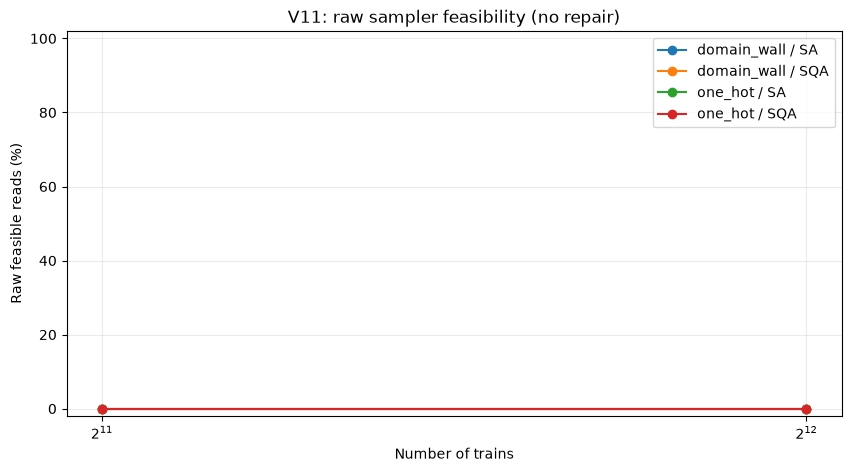

Repair post-processing disabled in V11; see V10 for the separate repair experiment.


In [ ]:
if not sampler_runs.empty:
    main_runs=sampler_runs[sampler_runs.phase=="MAIN"].copy()
    scaling_summary=(main_runs.groupby(["n_trains","encoding","algorithm"],dropna=False)
        .agg(datasets=("dataset_id","nunique"),sampler_runs=("run_status","size"),
             successful_runs=("run_status",lambda x:int((x=="OK").sum())),
             datasets_with_raw_valid=("best_raw_valid_cost",lambda x:int(x.notna().groupby(main_runs.loc[x.index,"dataset_id"]).any().sum())),
             mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             median_raw_feasibility_pct=("raw_feasibility_pct","median"),
             mean_repair_success_pct=("repair_success_pct","mean"),
             mean_best_raw_valid_cost=("best_raw_valid_cost","mean"),
             mean_best_repaired_cost=("best_repaired_cost","mean"),
             median_runtime_s=("runtime_s","median"),
             wins_raw_over_greedy=("gap_best_raw_valid_to_best_greedy",lambda x:int((x<0).sum())),
             wins_repaired_over_greedy=("gap_best_repaired_to_best_greedy",lambda x:int((x<0).sum())))
        .reset_index())

    by_dataset=(main_runs.groupby(["dataset_id","n_trains","difficulty","encoding","algorithm"])
        .agg(mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             best_raw_valid_cost=("best_raw_valid_cost","min"),
             mean_repair_success_pct=("repair_success_pct","mean"),
             best_repaired_cost=("best_repaired_cost","min"),
             median_runtime_s=("runtime_s","median")).reset_index())
    encoding_paired=(by_dataset.pivot_table(index=["dataset_id","n_trains","difficulty","algorithm"],
        columns="encoding",values=["mean_raw_feasibility_pct","best_raw_valid_cost",
        "mean_repair_success_pct","best_repaired_cost","median_runtime_s"],aggfunc="first").reset_index())
    encoding_paired.columns=["_".join([str(x) for x in c if str(x) not in ("","None")]).rstrip("_")
        if isinstance(c,tuple) else str(c) for c in encoding_paired.columns]

    repair_summary=(main_runs.groupby(["n_trains","encoding","algorithm"])
        .agg(mean_raw_feasibility_pct=("raw_feasibility_pct","mean"),
             mean_repair_success_pct=("repair_success_pct","mean"),
             mean_best_raw_valid_cost=("best_raw_valid_cost","mean"),
             mean_best_repaired_cost=("best_repaired_cost","mean"),
             repaired_runs=("best_repaired_cost",lambda x:int(x.notna().sum())),
             mean_domain_wall_order_transitions=("mean_domain_wall_order_violation_transitions_per_read","mean"),
             mean_constraint_violations=("mean_total_constraint_violations_per_read","mean"))
        .reset_index())

    greedy_comparison=(dataset_diagnostics.groupby("n_trains").agg(
        datasets=("dataset_id","nunique"),
        interval_greedy_feasible_rate=("greedy_interval_feasible","mean"),
        mrv_greedy_feasible_rate=("greedy_mrv_feasible","mean"),
        interval_greedy_mean_cost=("greedy_interval_cost","mean"),
        mrv_greedy_mean_cost=("greedy_mrv_cost","mean"),
        best_greedy_mean_cost=("best_greedy_cost","mean")).reset_index())

    print("Main scaling summary:"); display(scaling_summary)
    print("Paired encoding comparison (same dataset and algorithm):"); display(encoding_paired.head(20))
    print("Constraint diagnostic summary (repair is disabled in V11):"); display(repair_summary)
    print("Greedy baselines:"); display(greedy_comparison)

    # Plot 1: raw feasibility — the primary, unrepaired measure.
    fig,ax=plt.subplots(figsize=(10,5))
    for (enc,alg),d in scaling_summary.groupby(["encoding","algorithm"]):
        d=d.sort_values("n_trains")
        ax.plot(d.n_trains,d.mean_raw_feasibility_pct,marker="o",label=f"{enc} / {alg}")
    ax.set_xscale("log",base=2); ax.set_ylim(-2,102); ax.set_xlabel("Number of trains")
    ax.set_ylabel("Raw feasible reads (%)"); ax.set_title("V11: raw sampler feasibility (no repair)")
    ax.grid(alpha=.25); ax.legend(); plt.show()

    # V11 intentionally disables sample-level repair to focus on raw high-scale sampling.
    print("Repair post-processing disabled in V11; see V10 for the separate repair experiment.")

    # Plot 2: domain-wall platform ordering sensitivity (disabled in V11).
    if not platform_order_runs.empty:
        fig,ax=plt.subplots(figsize=(9,5))
        z=platform_order_runs.groupby(["n_trains","algorithm","platform_permutation_index"]).raw_feasibility_pct.mean().reset_index()
        for (alg,perm),d in z.groupby(["algorithm","platform_permutation_index"]):
            ax.plot(d.n_trains,d.raw_feasibility_pct,marker="o",label=f"{alg}, permutation {perm}")
        ax.set_xscale("log",base=2); ax.set_ylim(-2,102); ax.set_xlabel("Number of trains")
        ax.set_ylabel("Raw feasible reads (%)"); ax.set_title("V11 platform-label ordering probe (disabled)")
        ax.grid(alpha=.25); ax.legend(); plt.show()
else:
    scaling_summary=encoding_paired=repair_summary=greedy_comparison=pd.DataFrame()

## 13. Exploratory high-budget and 16,384 preflight outputs

These outputs are supplemental. The high-budget 8,192 confirmation is a conditional diagnostic and is never merged into the primary MAIN scaling summary. The 16,384 stage is a structural resource estimate only: `full_qubo_materialized` and `sampler_invoked` must remain `False` for every preflight row.


In [ ]:
print("Primary MAIN calls:", int((sampler_runs.phase == "MAIN").sum()) if not sampler_runs.empty else 0)
print("Conditional 8,192 high-budget calls:", len(budget_escalation_runs))
print("16,384 preflight rows:", len(preflight_16384_metrics))
if not budget_escalation_runs.empty:
    display(budget_escalation_runs.groupby(["encoding","algorithm"]).agg(
        runs=("dataset_id","size"),valid_reads=("valid_reads","sum"),
        reads=("total_reads","sum"),median_runtime_s=("runtime_s","median")).reset_index())
if not preflight_16384_metrics.empty:
    display(preflight_16384_metrics.groupby(["encoding","resource_estimate_status"]).agg(
        models=("dataset_id","size"),mean_variables=("n_variables_estimate","mean"),
        max_interactions_upper_bound=("quadratic_interactions_upper_bound","max")).reset_index())


Primary MAIN calls: 48
Conditional 8,192 high-budget calls: 0
16,384 preflight rows: 0


## 12. Export results and metadata

PILOT and FULL are exported to separate directories. Retain all CSVs, metadata and the executed notebook together.

In [ ]:
OUTPUT_DIR=Path.cwd()/f"railway_v11_outputs_{STUDY_MODE.lower()}"
OUTPUT_DIR.mkdir(parents=True,exist_ok=True)

def export_frame(frame,name):
    if frame is None or frame.empty:
        print("Not exported (empty):",name); return
    path=OUTPUT_DIR/name; frame.to_csv(path,index=False); print("Saved:",path)

export_frame(dataset_diagnostics,"railway_v11_dataset_diagnostics.csv")
export_frame(generated_train_tables,"railway_v11_generated_train_tables.csv")
export_frame(conflict_edge_tables,"railway_v11_conflict_edges.csv")
export_frame(qubo_model_metrics,"railway_v11_qubo_model_metrics.csv")
export_frame(sampler_runs,"railway_v11_sampler_runs.csv")
export_frame(raw_sample_diagnostics_table,"railway_v11_raw_sample_diagnostics.csv")
export_frame(scaling_summary,"railway_v11_scaling_summary.csv")
export_frame(encoding_paired,"railway_v11_paired_encoding_comparison.csv")
export_frame(repair_summary,"railway_v11_repair_summary.csv")
export_frame(greedy_comparison,"railway_v11_greedy_comparison.csv")
export_frame(platform_order_runs,"railway_v11_platform_order_sensitivity.csv")
export_frame(budget_escalation_runs,"railway_v11_8192_budget_escalation.csv")
export_frame(preflight_16384_metrics,"railway_v11_16384_resource_preflight.csv")

metadata={
    "notebook_version":"v11_exploratory_high_scale_stress_test",
    "study_mode":STUDY_MODE,"python_version":sys.version.split()[0],"platform":platform.platform(),
    "cpu":platform.processor(),"ram_gb":RAM_GB,"openjij_version":OPENJIJ_VERSION,
    "n_platforms":N_PLATFORMS,"long_platform_count":LONG_PLATFORM_COUNT,
    "long_train_coach_threshold":LONG_TRAIN_COACH_THRESHOLD,"clearance_min_assumption":CLEARANCE_MIN,
    "train_counts":TRAIN_COUNTS,"seeds_by_size":SEEDS_BY_SIZE,"difficulty_levels":DIFFICULTIES,
    "difficulty_config":DIFFICULTY_CONFIG,"dataset_count":len(dataset_diagnostics),
    "encodings":ENCODINGS,"algorithms":ALGORITHMS,"encoding_penalty_rules":{
        "one_hot":"U+1 for assignment and conflict penalties, where U is best validated feasible Greedy cost",
        "domain_wall":"conflict=U+1; monotonicity=(U+1)*(Rmax+1)*max_conflict_degree+U+2; eligibility is structural",
        "proof_note":"For train i, r_i forbidden 0-to-1 transitions imply indicator negative mass r_i and positive mass r_i+1. The per-edge conflict lower bound is -(Rmax+1)*(r_i+r_j); the reassignment objective is nonnegative because each individual platform indicator is at most one. The stated monotonicity penalty makes every wall-invalid state strictly more expensive than the feasible incumbent U. For wall-valid states, conflict=U+1 excludes conflicting states from the ground state."
    },
    "budgets":BUDGET_BY_SIZE,"repair_method":"disabled in V11 to focus on raw high-scale sampler behaviour; V11 retains the separate repair experiment",
    "repair_restarts":0,"raw_vs_repaired":"Repair is disabled in V11; raw samples are the sole sampler outcome",
    "platform_order_probe_datasets":ORDER_PROBE_DATASETS,"alternate_platform_orders_per_dataset":N_ALTERNATE_PLATFORM_ORDERS,
    "expected_dataset_count":EXPECTED_DATASETS,"planned_main_sampler_calls":EXPECTED_MAIN_CALLS,
    "planned_platform_order_calls":EXPECTED_ORDER_CALLS,"planned_total_sampler_calls":EXPECTED_CALLS,
    "maximum_conditional_escalation_calls":len(DIFFICULTIES)*len(ENCODINGS)*len(ALGORITHMS),
    "actual_sampler_rows":len(sampler_runs),"sampler_error_rows":int((sampler_runs.run_status=="ERROR").sum()) if not sampler_runs.empty else 0,
    "resource_skips":0,"max_qubo_variables":MAX_QUBO_VARIABLES,"max_qubo_interactions":MAX_QUBO_INTERACTIONS,
    "conditional_8192_confirmation_enabled":RUN_8192_BUDGET_CONFIRMATION,
    "conditional_8192_confirmation_calls":len(budget_escalation_runs),
    "conditional_8192_confirmation_rule":"Triggered per encoding/algorithm only when its total valid MAIN reads across all 8,192 datasets is zero; selected data seed 11 for each difficulty; 64 reads, 400 sweeps, repeat id 99.",
    "preflight_16384_enabled":RUN_16384_PREFLIGHT and STUDY_MODE.upper()=="FULL",
    "preflight_16384_estimate_rows":len(preflight_16384_metrics),
    "preflight_16384_sampler_calls":0,
    "preflight_16384_full_qubos_materialized":False,
    "preflight_16384_method":"exact variable counts; one-hot interaction count from eligibility/conflicts; conservative domain-wall interaction upper bound; no full QUBO materialization",
    "preflight_16384_caps":{"variables":PREFLIGHT_MAX_VARIABLES,"interactions":PREFLIGHT_MAX_INTERACTIONS},
    "main_calls_expected":EXPECTED_MAIN_CALLS,
    "main_calls_actual":int((sampler_runs.phase=="MAIN").sum()) if not sampler_runs.empty else 0,
    "escalation_calls_actual":len(budget_escalation_runs),
    "synthetic_data_notice":"All schedules, delays, nominal platforms, coach counts and conflicts are synthetic; no station-specific dataset is used.",
    "witness_notice":"A known feasible witness validates the generator and may supply a documented feasible upper-bound fallback; it is never passed to either sampler.",
    "quantum_notice":"OpenJij SQA is a classical simulation, not quantum hardware.",
    "exact_search_notice":"No exact search is run in V11 because the selected sizes start at 64; exact reference results for <=32 trains are retained from earlier versions.",
    "interpretation_notice":"A valid QUBO ground state does not imply finite-budget SA/SQA samples are valid. Conditional high-budget runs are reported separately from MAIN runs. Repair is disabled in V11; the 16,384 stage is a structural resource estimate, not a built or sampled QUBO.",
}
with open(OUTPUT_DIR/"railway_v11_experiment_metadata.json","w",encoding="utf-8") as f: json.dump(metadata,f,indent=2)
print("V11 outputs saved to:",OUTPUT_DIR.resolve())

Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_dataset_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_generated_train_tables.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_conflict_edges.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_qubo_model_metrics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_sampler_runs.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_raw_sample_diagnostics.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_scaling_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_paired_encoding_comparison.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\DL_sem_5\railway_v11_outputs_pilot\railway_v11_repair_summary.csv
Saved: c:\Users\AIDSHPCLAB06\Desktop\

## 14. Final V11 stopping and reporting checklist

- [ ] PILOT completes with both encodings and both algorithms on the 2,048/4,096-train pilot datasets.
- [ ] FULL includes 2,048, 4,096 and 8,192 sampler sizes with the registered seeds and matched SA/SQA/encoding budgets.
- [ ] The sweep-line conflict builder is checked against the original pairwise overlap predicate on small instances.
- [ ] Both encodings pass QUBO identity tests for every main dataset.
- [ ] Raw feasibility and each constraint family are reported independently.
- [ ] Conditional 8,192 high-budget confirmation, if triggered, is reported separately from MAIN runs.
- [ ] The 16,384-train stage is a structural resource estimate only; no full QUBO is materialized and no sampler is called at that size.
- [ ] Any estimate above the preflight resource caps is reported as over-cap; 16,384 is never sampled.
- [ ] Repair is clearly marked disabled in V11; V10 remains the source for the repair experiment.
- [ ] SQA is described as a classical simulation; no quantum-hardware or quantum-advantage claim is made.
- [ ] V8–V10 outputs remain unchanged and are preserved.

**Final stopping rule:** after V11 FULL and its preflight/confirmation outputs are reviewed, freeze the computational experiments and proceed to statistical analysis and research-paper finalization. Do not create V12 or increase the scale further unless a reproducible correctness defect is found.
